# Lab 8: A Hawkes Model for Large Stock-Return Events

Student: Lopatenko George (334771)  
Course: Machine Learning for Time Series (TSML)

Large stock returns often arrive in episodes of elevated activity. I model the timing of threshold exceedances in SPY daily log returns, generate new event sequences, and compare their intervals, magnitudes and counts with a later observation period. A homogeneous Poisson model supplies the reference without self-excitation.

In [1]:
import os
from pathlib import Path

for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"]:
    os.environ[variable] = "1"

import textwrap

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, display
from plotly.subplots import make_subplots
from prettytable import PrettyTable

SEED = 42
TSML_DIR = next(path for path in [Path.cwd(), Path.cwd() / "tsml", Path.cwd().parent]
                if (path / "lab-2/data/SPY_AdjClose.csv").exists())
COLORS = {"Hawkes": "#D55E00", "Poisson": "#0072B2", "Observed": "#252525"}


def show_table(frame, title, decimals=3):
    table = PrettyTable()
    table.title = title
    table.field_names = list(frame.columns)
    table.align = "l"
    for row in frame.itertuples(index=False, name=None):
        table.add_row([f"{value:.{decimals}f}" if isinstance(value, (float, np.floating)) else value for value in row])
    print(table)


def show_figure(fig, caption, height=750):
    has_legend = fig.layout.showlegend is not False and any(trace.showlegend is not False for trace in fig.data)
    top = 155 if has_legend else 110
    bottom = 180
    for annotation in fig.layout.annotations:
        annotation.font = dict(size=19, color="#252525")
    fig.update_layout(
        template="plotly_white", width=1080, height=height,
        font=dict(family="Arial", size=20, color="#252525"),
        title=dict(x=0.025, xanchor="left", y=1-20/height, yanchor="top", font=dict(size=26)),
        margin=dict(l=110, r=45, t=top, b=bottom),
        legend=dict(orientation="h", x=0, y=1+65/(height-top-bottom), yanchor="bottom", title_text=""),
        hovermode="closest",
    )
    fig.update_xaxes(showgrid=False, zeroline=False, ticks="outside", ticklen=4)
    fig.update_yaxes(gridcolor="#E5E7EB", zeroline=False, ticks="outside", ticklen=4)
    caption = "<br>".join(textwrap.wrap(caption, width=87))
    fig.add_annotation(
        text=caption, x=0, y=0, yshift=-95, xref="paper", yref="paper",
        showarrow=False, xanchor="left", yanchor="top", align="left",
        font=dict(size=18, color="#555555"),
    )
    display(Image(data=fig.to_image(format="png", scale=2), alt=fig.layout.title.text + ". " + caption.replace("<br>", " ")))


## 1. Prices, returns and the observation clock

The retained Yahoo Finance SPY snapshot contains 1,254 prices from 2021-09-22 to 2026-09-21. SPY is an exchange-traded fund tracking a broad US equity index. I use the saved `Close` values without assuming that the column establishes a particular dividend-adjustment convention.

The return is $r_d=\log P_d-\log P_{d-1}$. The first 1,002 returns form the training period; the final 251 form the held-out period beginning 2025-09-22. Time is measured in trading sessions, so weekends do not create artificial long intervals. An event occupies the midpoint of its session, $t=d+0.5$.

The daily return series is irregular and has clustered large moves. Neither a jagged trace nor a successful Hawkes fit establishes deterministic chaos; the model describes event clustering.

## 2. Defining a breakthrough

An event occurs on **every session** with $|r_d|>u$, including consecutive exceedance sessions. This is an exceedance process, not only the first crossing into a high-volatility episode. Positive and negative moves share one event stream. Its mark is the absolute log-return magnitude $m=|r_d|$.

I fix $u$ at the training 80th percentile of $|r_d|$: **1.253%**. This produces **201 training events** and **31 held-out events**. The threshold is not changed to make the test result favourable. The held-out interval distribution therefore contains only 30 complete gaps, which limits precision.

The following sensitivity check uses training data only. More extreme thresholds leave fewer observations, while fitted excitation remains present across this range.


## 3. Conditional intensity and estimation

The exponential model has conditional intensity

$$
\lambda(t)=\mu+\eta\beta\sum_{t_i<t}e^{-\beta(t-t_i)}.
$$

Each event raises the intensity by $\eta\beta$, then its contribution decays. The kernel integrates to $\eta$, the branching ratio; $\eta<1$ gives a stationary mean rate $\mu/(1-\eta)$. The implementation follows the standard likelihood and thinning construction reviewed by [Laub, Taimre and Pollett](https://arxiv.org/abs/1507.02822).

For an observation window $[0,T)$ with no prehistory, the log-likelihood is

$$
\ell=\sum_i\log\lambda(t_i)-\mu T-\eta\sum_i\left[1-e^{-\beta(T-t_i)}\right].
$$

Nine bounded optimization starts cover several branching and decay values. The constraints are $\mu>0$, $0<\eta\leq0.98$ and $0.005\leq\beta\leq1$ per session. The upper decay bound avoids interpreting an unobserved sub-session time scale. The whole observation window enters the integral, including the quiet tail after its last event. Test likelihood carries excitation from the training events and updates it using observed earlier test events, while keeping all parameters fixed.

In [2]:
"""Exponential Hawkes likelihood, conditional simulation and event diagnostics."""

import numpy as np
from scipy.optimize import minimize
from scipy.stats import entropy, wasserstein_distance


def excitation_before(events, time, beta):
    past = np.asarray(events)[np.asarray(events) < time]
    return float(np.exp(-beta * (time - past)).sum())


def hawkes_log_likelihood(params, events, start, end, past=()):
    mu, branching, beta = params
    events = np.asarray(events, dtype=float)
    initial = excitation_before(np.asarray(past), start, beta)
    state, previous = initial, start
    log_intensity = 0.0
    for event in events:
        state *= np.exp(-beta * (event - previous))
        log_intensity += np.log(mu + branching * beta * state)
        state += 1.0
        previous = event
    integral = mu * (end - start)
    integral += branching * initial * (-np.expm1(-beta * (end - start)))
    integral += branching * (-np.expm1(-beta * (end - events))).sum()
    return float(log_intensity - integral)


def fit_hawkes(events, end):
    rate = len(events) / end
    attempts = []
    # Multiple starts reduce sensitivity to the non-convex decay parameter.
    for branching in (0.2, 0.6, 0.85):
        for beta in (0.02, 0.1, 0.5):
            result = minimize(
                lambda params: -hawkes_log_likelihood(params, events, 0.0, end),
                x0=[rate * (1 - branching), branching, beta],
                method="L-BFGS-B",
                bounds=[(1e-6, 2.0), (1e-6, 0.98), (0.005, 1.0)],
            )
            if result.success and np.isfinite(result.fun):
                attempts.append(result)
    if not attempts:
        raise RuntimeError("No Hawkes optimization start converged.")
    best = min(attempts, key=lambda result: result.fun)
    return best.x, attempts


def simulate_hawkes(params, duration, rng, initial_state=0.0):
    mu, branching, beta = params
    time, excess = 0.0, branching * beta * initial_state
    events = []
    while time < duration:
        upper = mu + excess
        wait = rng.exponential(1.0 / upper)
        time += wait
        if time >= duration:
            break
        excess *= np.exp(-beta * wait)
        if rng.random() < (mu + excess) / upper:
            events.append(time)
            excess += branching * beta
        if len(events) > 100000:
            raise RuntimeError("Simulation exceeded the event budget.")
    return np.asarray(events)


def simulate_poisson(rate, duration, rng):
    n = rng.poisson(rate * duration)
    return np.sort(rng.uniform(0, duration, n))


def daily_events(times, n_days):
    # Daily closes can reveal at most one threshold event per trading session.
    return np.unique(np.floor(times).astype(int).clip(0, n_days - 1))


def count_blocks(event_days, n_days, width=20):
    n_complete = n_days // width
    kept = np.asarray(event_days)[np.asarray(event_days) < n_complete * width]
    counts, _ = np.histogram(kept, bins=np.arange(n_complete + 1) * width)
    return counts


def smoothed_pmf(values, edges):
    counts = np.histogram(values, bins=edges)[0].astype(float)
    return (counts + 0.5) / (counts.sum() + 0.5 * len(counts))


def distribution_distances(observed, simulated, edges):
    """W1 on raw samples; KL(observed || simulated) on shared, smoothed bins."""
    p = smoothed_pmf(observed, edges)
    q = smoothed_pmf(simulated, edges)
    middle = 0.5 * (p + q)
    return {
        "wasserstein": float(wasserstein_distance(observed, simulated)),
        "kl": float(entropy(p, q, base=np.e)),
        "js": float(0.5 * entropy(p, middle, base=np.e) + 0.5 * entropy(q, middle, base=np.e)),
    }


def integrated_gaps(params, events, start, past=()):
    mu, branching, beta = params
    state = excitation_before(np.asarray(past), start, beta)
    previous = start
    increments = []
    for event in events:
        gap = event - previous
        increments.append(mu * gap + branching * state * (-np.expm1(-beta * gap)))
        state = state * np.exp(-beta * gap) + 1.0
        previous = event
    return np.asarray(increments)

### Simulation and event magnitudes

Ogata thinning proposes the next event from an exponential waiting time at the current upper intensity. Excitation decays during that wait; the candidate is accepted with probability equal to the new intensity divided by its upper bound. An accepted event adds a new excitation jump. Simulations begin with the excitation remaining at the end of training.

A timing process does not predict return magnitude by itself. I add a separate, train-fitted mark model: $\log(m-u)$ is Gaussian, so a simulated magnitude is $m=u+\exp(Z)$. Marks are independent of event history in this model. Both Hawkes and Poisson use this same mark law, so magnitude accuracy tests that law rather than demonstrating a benefit from self-excitation.

For observation-level comparisons, simulated continuous times are grouped into occupied trading sessions. If several arrivals fall in one session, it is counted once and assigned one mark. Daily closing data cannot resolve their order or number. This binning changes the latent event rate, so the number of occupied sessions is checked explicitly.

In [3]:
from scipy.stats import kstest

N_SIMULATIONS = 300
prices = pd.read_csv(TSML_DIR / "lab-2/data/SPY_AdjClose.csv", parse_dates=["Date"]).dropna().sort_values("Date")
price_column = next(name for name in ["SPY", "Adj Close", "Close"] if name in prices)
prices = prices[["Date", price_column]].rename(columns={price_column: "price"})
if prices.Date.duplicated().any() or (prices.price <= 0).any():
    raise ValueError("Prices must be positive and dates unique.")
returns = np.diff(np.log(prices.price.to_numpy()))
dates = prices.Date.iloc[1:].reset_index(drop=True)
n_train = int(len(returns) * 0.8)
n_test = len(returns) - n_train
threshold = float(np.quantile(np.abs(returns[:n_train]), 0.8))
event_mask = np.abs(returns) > threshold
times = np.flatnonzero(event_mask).astype(float) + 0.5
train_times = times[times < n_train]
test_times = times[times >= n_train]
test_days = np.floor(test_times - n_train).astype(int)
train_levels = np.abs(returns[:n_train][event_mask[:n_train]])
test_levels = np.abs(returns[n_train:][event_mask[n_train:]])

threshold_rows = []
for quantile in (0.75, 0.8, 0.85, 0.9):
    level = np.quantile(np.abs(returns[:n_train]), quantile)
    selected_times = np.flatnonzero(np.abs(returns[:n_train]) > level) + 0.5
    fitted, _ = fit_hawkes(selected_times, n_train)
    threshold_rows.append({"quantile": quantile, "threshold_pct": level * 100, "train_events": len(selected_times), "branching": fitted[1], "half_life_days": np.log(2) / fitted[2]})

params, attempts = fit_hawkes(train_times, n_train)
mu, branching, beta = params
poisson_rate = len(train_times) / n_train
train_excess = train_levels - threshold
mark_log_mean, mark_log_sd = float(np.log(train_excess).mean()), float(np.log(train_excess).std(ddof=1))

model_rows = []
residual_frames = {}
for model, fitted, n_parameters in [("Hawkes", params, 3), ("Poisson", [poisson_rate, 0.0, beta], 1)]:
    train_ll = hawkes_log_likelihood(fitted, train_times, 0.0, n_train)
    test_ll = hawkes_log_likelihood(fitted, test_times, n_train, len(returns), train_times)
    residuals = integrated_gaps(fitted, test_times, n_train, train_times)
    # Exclude the boundary-to-first-event interval from inter-event diagnostics.
    uniforms = -np.expm1(-residuals[1:])
    model_rows.append({"model": model, "train_log_likelihood": train_ll, "train_aic": 2 * n_parameters - 2 * train_ll, "test_log_likelihood": test_ll, "test_ll_per_day": test_ll / n_test, "rescaled_mean": residuals[1:].mean(), "rescaled_ks_d": kstest(uniforms, "uniform").statistic})
    residual_frames[model] = pd.DataFrame({"integrated_gap": residuals[1:], "uniform_residual": uniforms})

gap_edges = np.array([0.5, 1.5, 2.5, 3.5, 5.5, 10.5, 20.5, 40.5, np.inf])
level_edges = np.r_[threshold, np.unique(np.quantile(train_levels, [0.25, 0.5, 0.75, 0.9, 0.95])), np.inf]
observed_gaps = np.diff(test_days)
observed_counts = count_blocks(test_days, n_test)
simulation_rows, simulated_events, count_rows = [], [], []
for model in ("Hawkes", "Poisson"):
    for repetition in range(N_SIMULATIONS):
        rng = np.random.default_rng(SEED + repetition)
        if model == "Hawkes":
            initial = excitation_before(train_times, n_train, beta)
            continuous = simulate_hawkes(params, n_test, rng, initial)
        else:
            continuous = simulate_poisson(poisson_rate, n_test, rng)
        days = daily_events(continuous, n_test)
        levels = threshold + rng.lognormal(mark_log_mean, mark_log_sd, len(days))
        gaps = np.diff(days)
        if len(gaps) == 0:
            raise RuntimeError("Too few simulated events for distribution diagnostics.")
        counts = count_blocks(days, n_test)
        gap_distances = distribution_distances(observed_gaps, gaps, gap_edges)
        level_distances = distribution_distances(test_levels * 100, levels * 100, level_edges * 100)
        count_distances = distribution_distances(observed_counts, counts, np.r_[np.arange(-0.5, 20.5), np.inf])
        simulation_rows.append({
            "model": model, "simulation": repetition, "events": len(days),
            "within_day_collisions": len(continuous) - len(days),
            "mean_gap_days": gaps.mean(),
            **{f"gap_{name}": value for name, value in gap_distances.items()},
            **{f"level_{name}": value for name, value in level_distances.items()},
            **{f"count_{name}": value for name, value in count_distances.items()},
            "count_fano": counts.var(ddof=1) / counts.mean() if counts.mean() else np.nan,
        })
        simulated_events.extend({"model": model, "simulation": repetition, "day": int(day), "level_pct": level * 100} for day, level in zip(days, levels))
        count_rows.extend({"model": model, "simulation": repetition, "block": block, "count": int(count)} for block, count in enumerate(counts, 1))

simulations = pd.DataFrame(simulation_rows)
event_frame = pd.DataFrame({"date": dates[event_mask].to_numpy(), "time": times, "partition": np.where(times < n_train, "Train", "Test"), "log_return_pct": returns[event_mask] * 100, "level_pct": np.abs(returns[event_mask]) * 100})

summary = []
for model, group in simulations.groupby("model"):
    row = {"model": model}
    for metric in ["events", "gap_wasserstein", "gap_kl", "gap_js", "level_wasserstein", "level_kl", "level_js", "count_wasserstein", "count_fano", "within_day_collisions"]:
        row[f"{metric}_median"] = group[metric].median()
        row[f"{metric}_q025"] = group[metric].quantile(0.025)
        row[f"{metric}_q975"] = group[metric].quantile(0.975)
    summary.append(row)

report = {
    "n_returns": len(returns), "n_train": n_train, "n_test": n_test,
    "threshold": threshold, "train_events": len(train_times), "test_events": len(test_times),
    "mu": mu, "branching": branching, "beta": beta, "half_life_days": np.log(2) / beta,
    "poisson_rate": poisson_rate, "stationary_rate": mu / (1 - branching),
    "mark_log_mean": mark_log_mean, "mark_log_sd": mark_log_sd,
    "test_count_fano": observed_counts.var(ddof=1) / observed_counts.mean(),
    "successful_optimizer_starts": len(attempts), "n_simulations_per_model": N_SIMULATIONS,
    "train_end": str(dates.iloc[n_train - 1]), "test_start": str(dates.iloc[n_train]),
    "gap_bin_edges": [str(x) for x in gap_edges], "level_bin_edges_pct": [str(x * 100) for x in level_edges],
}
sensitivity = pd.DataFrame(threshold_rows)
likelihood = pd.DataFrame(model_rows)
simulation_summary = pd.DataFrame(summary)
simulated = pd.DataFrame(simulated_events)
count_frame = pd.DataFrame(count_rows)
daily = pd.DataFrame({"date": dates, "log_return_pct": returns * 100, "event": event_mask})
observed = event_frame
fit = report


In [4]:
show_table(sensitivity.rename(columns={
    "quantile": "Train quantile", "threshold_pct": "Threshold (%)",
    "train_events": "Events", "branching": "Branching", "half_life_days": "Half-life (sessions)"
}), "Training-only threshold sensitivity")


+----------------------------------------------------------------------------+
|                    Training-only threshold sensitivity                     |
+----------------+---------------+--------+-----------+----------------------+
| Train quantile | Threshold (%) | Events | Branching | Half-life (sessions) |
+----------------+---------------+--------+-----------+----------------------+
| 0.750          | 1.114         | 251    | 0.696     | 13.794               |
| 0.800          | 1.253         | 201    | 0.736     | 13.287               |
| 0.850          | 1.484         | 151    | 0.777     | 10.962               |
| 0.900          | 1.767         | 101    | 0.791     | 10.413               |
+----------------+---------------+--------+-----------+----------------------+


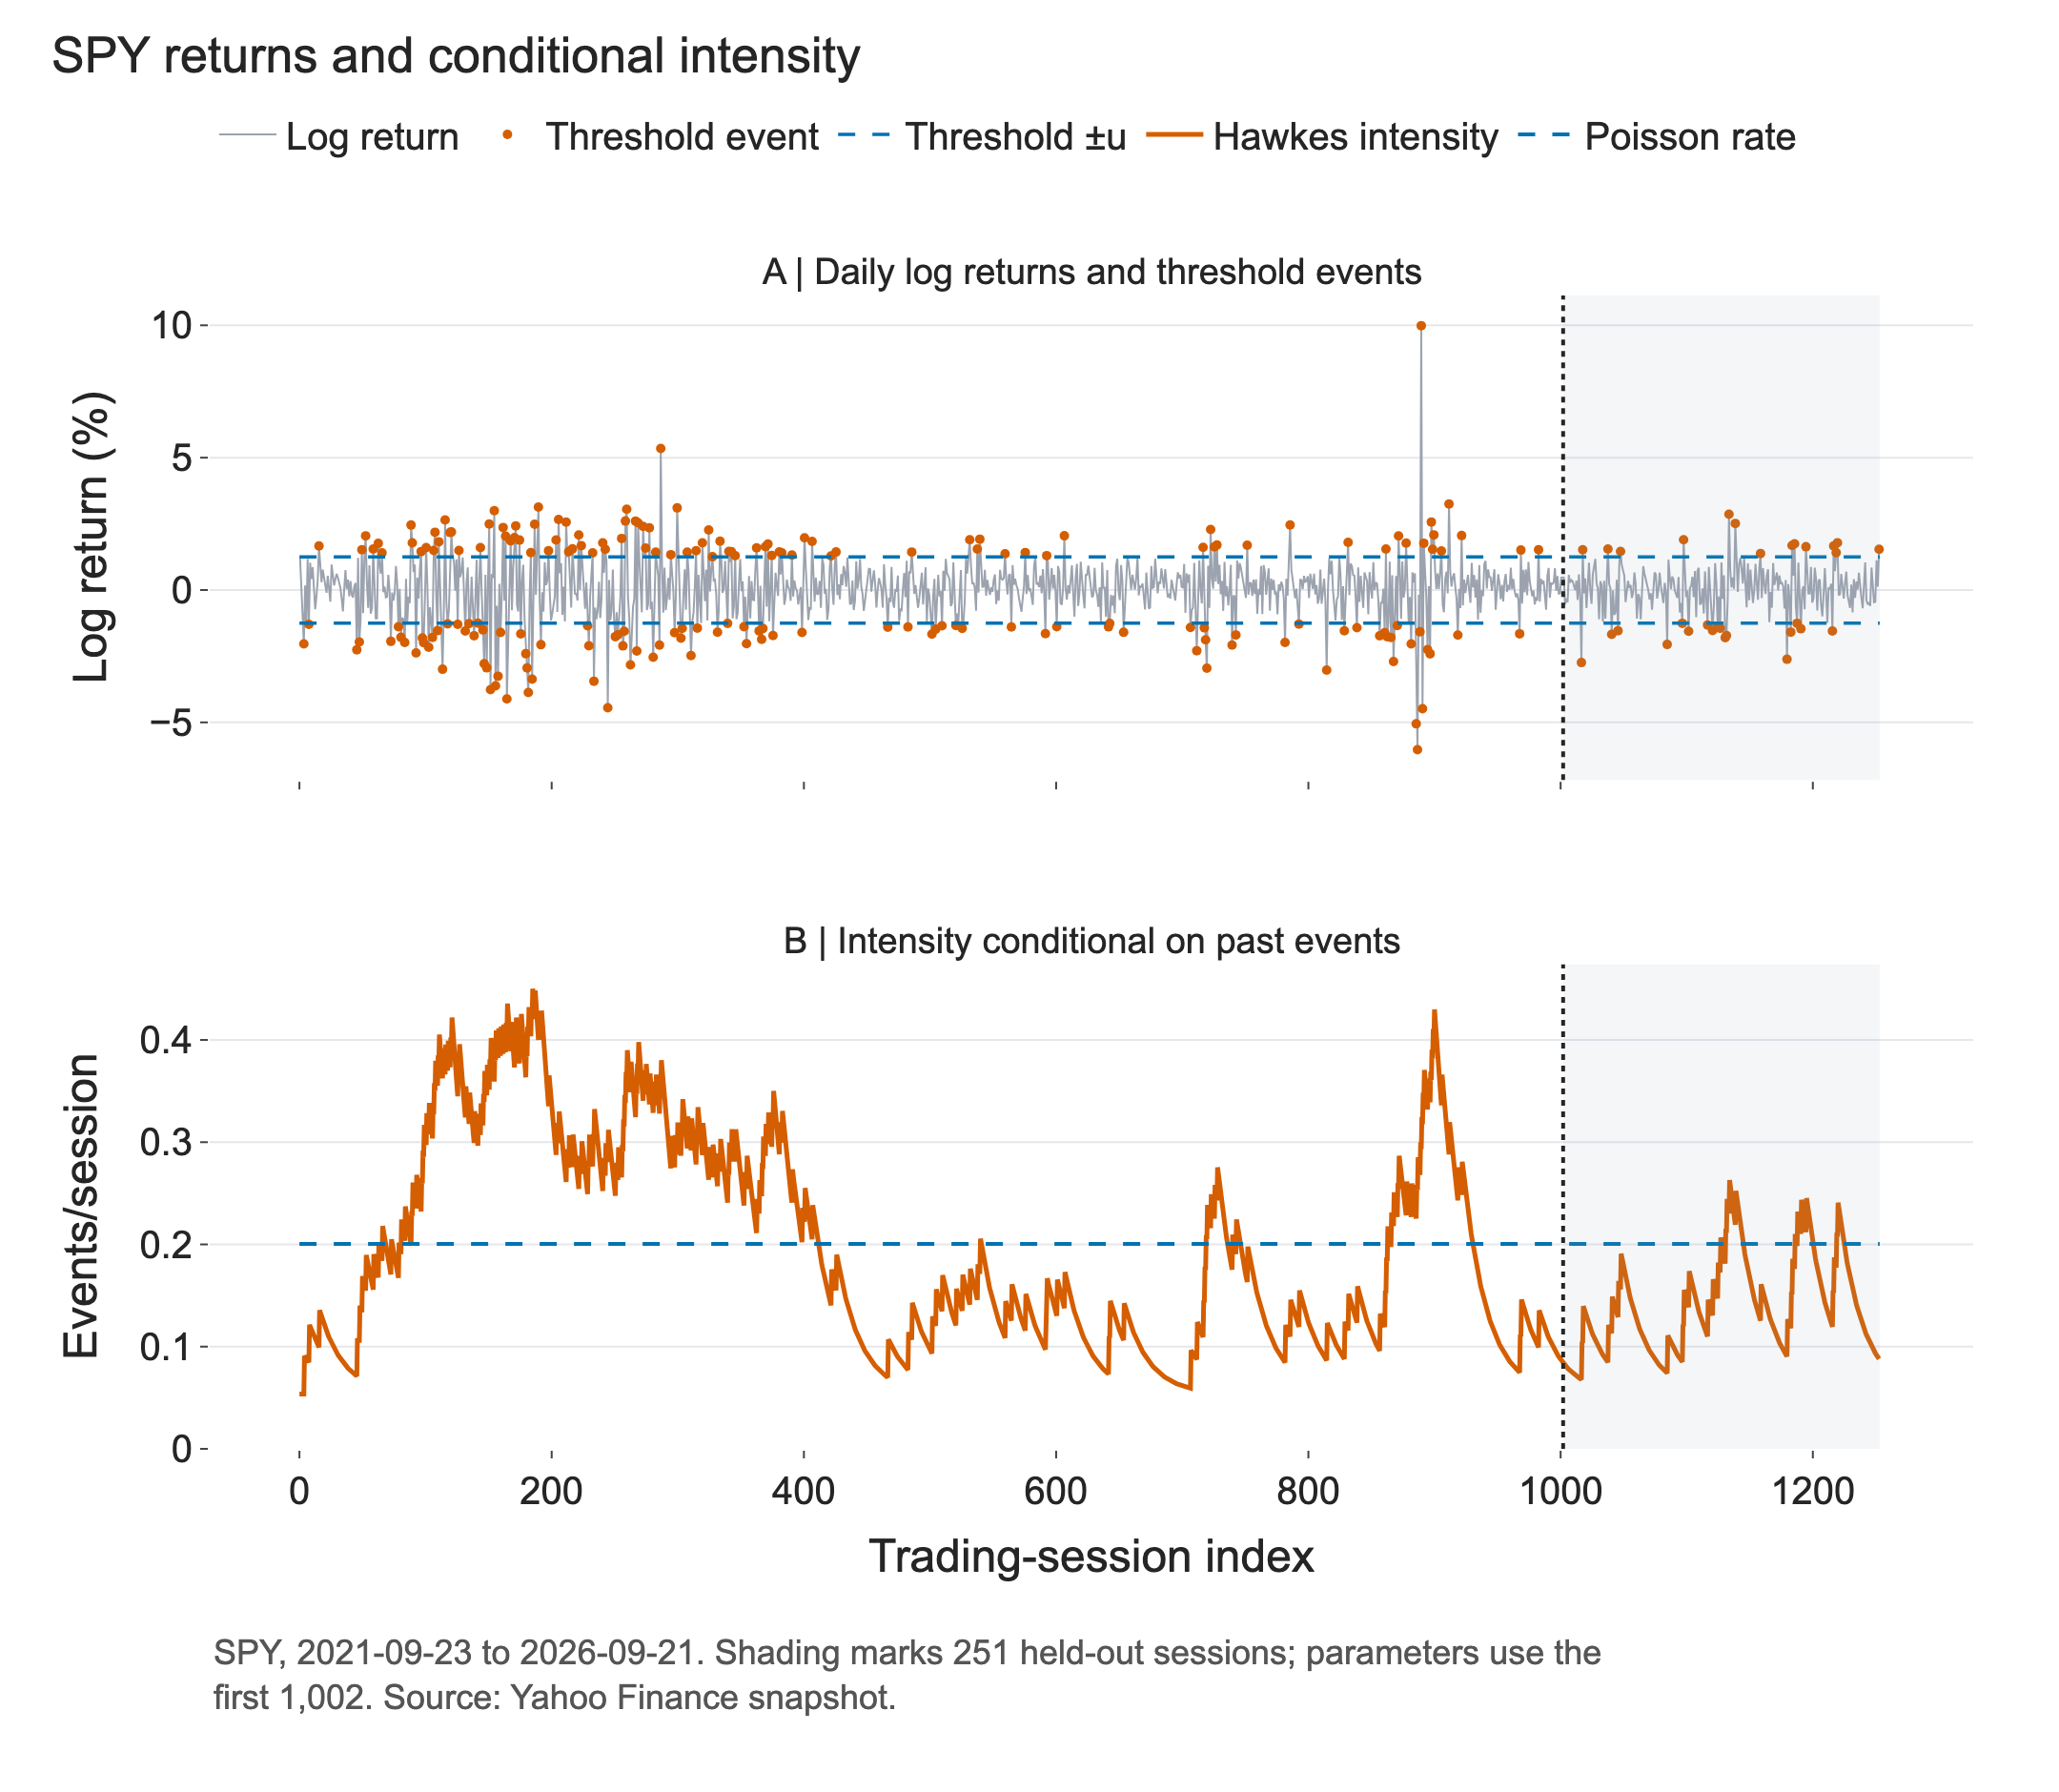

In [5]:
fig = make_subplots(
    rows=2, cols=1, shared_xaxes=True, vertical_spacing=0.16,
    subplot_titles=["A | Daily log returns and threshold events", "B | Intensity conditional on past events"],
)
session = np.arange(len(daily)) + 0.5
fig.add_trace(go.Scatter(
    x=session, y=daily.log_return_pct, name="Log return",
    mode="lines", line=dict(color="#9CA3AF", width=1),
), row=1, col=1)
fig.add_trace(go.Scatter(
    x=observed.time, y=observed.log_return_pct, name="Threshold event",
    mode="markers", marker=dict(size=5, color=COLORS["Hawkes"]),
), row=1, col=1)
for sign in (-1, 1):
    fig.add_trace(go.Scatter(
        x=[0, len(daily)], y=[sign * threshold * 100] * 2, name="Threshold ±u",
        showlegend=sign == 1, mode="lines", line=dict(color=COLORS["Poisson"], dash="dash", width=1.7),
    ), row=1, col=1)
grid = np.arange(0.0, len(daily), 0.5)
intensity = np.array([mu + branching * beta * excitation_before(times, t, beta) for t in grid])
fig.add_trace(go.Scatter(
    x=grid, y=intensity, name="Hawkes intensity", mode="lines",
    line=dict(color=COLORS["Hawkes"], width=2.5),
), row=2, col=1)
fig.add_trace(go.Scatter(
    x=[0, len(daily)], y=[poisson_rate] * 2, name="Poisson rate", mode="lines",
    line=dict(color=COLORS["Poisson"], dash="dash", width=2),
), row=2, col=1)
for row in (1, 2):
    fig.add_vrect(x0=n_train, x1=len(daily), fillcolor="#94A3B8", opacity=0.10, line_width=0, row=row, col=1)
    fig.add_vline(x=n_train, line_dash="dot", line_color="#252525", row=row, col=1)
fig.update_yaxes(title_text="Log return (%)", row=1, col=1)
fig.update_yaxes(title_text="Events/session", rangemode="tozero", row=2, col=1)
fig.update_xaxes(title_text="Trading-session index", row=2, col=1)
fig.update_layout(title="SPY returns and conditional intensity", showlegend=True)
show_figure(
    fig, "SPY, 2021-09-23 to 2026-09-21. Shading marks 251 held-out sessions; parameters use the first 1,002. Source: Yahoo Finance snapshot.",
    height=940,
)

## 4. Fit and held-out likelihood

The fitted half-life is 13.3 trading sessions, much longer than the daily observation resolution. The branching ratio describes the model's event mechanism; it is not a measured causal fraction of market moves. Shared volatility regimes can produce the same statistical clustering.

Higher log-likelihood and lower AIC are preferred. Hawkes improves training AIC by **49.11**, despite two extra timing parameters. The held-out log-likelihood advantage is only **3.11** over 251 sessions. This is evidence for some useful clustering information, not a decisive out-of-sample win.

The event times are rounded to daily midpoints. These are continuous-time pseudo-likelihoods at that resolution, rather than an exact interval-censored likelihood for daily closes. The bound on decay limits the mismatch but does not remove it.

In [6]:
parameters = pd.DataFrame({
    "Parameter": ["Background μ", "Branching η", "Decay β", "Half-life", "Stationary rate"],
    "Estimate": [mu, branching, beta, np.log(2)/beta, mu/(1-branching)],
    "Unit": ["events/session", "offspring/event", "1/session", "sessions", "events/session"],
})
show_table(parameters, "Exponential Hawkes fit")
show_table(likelihood[["model", "train_log_likelihood", "train_aic", "test_log_likelihood", "test_ll_per_day"]].rename(columns={
    "model": "Model", "train_log_likelihood": "Train log L", "train_aic": "Train AIC",
    "test_log_likelihood": "Test log L", "test_ll_per_day": "Test log L/day",
}), "Timing likelihood: higher log L is better")


+----------------------------------------------+
|            Exponential Hawkes fit            |
+-----------------+----------+-----------------+
| Parameter       | Estimate | Unit            |
+-----------------+----------+-----------------+
| Background μ    | 0.054    | events/session  |
| Branching η     | 0.736    | offspring/event |
| Decay β         | 0.052    | 1/session       |
| Half-life       | 13.287   | sessions        |
| Stationary rate | 0.203    | events/session  |
+-----------------+----------+-----------------+
+-----------------------------------------------------------------+
|            Timing likelihood: higher log L is better            |
+---------+-------------+-----------+------------+----------------+
| Model   | Train log L | Train AIC | Test log L | Test log L/day |
+---------+-------------+-----------+------------+----------------+
| Hawkes  | -497.342    | 1000.684  | -97.041    | -0.387         |
| Poisson | -523.896    | 1049.792  | -100.150   | -0

## 5. How the distributional errors are computed

For each model, 300 independent simulation seeds generate a new 251-session path. Hawkes paths inherit the excitation remaining at the training boundary; Poisson paths use the constant training event rate. Each path is reduced to occupied trading days. I compare its complete inter-event gaps with the **30 observed test gaps**, and its absolute-return marks with the **31 observed test marks**. The initial and terminal censored intervals are excluded from the gap sample; they remain accounted for in the point-process likelihood.

### Wasserstein-1: an unbinned distance with physical units

For observed sample $x_1,\ldots,x_n$ and simulated sample $y_1,\ldots,y_m$, let $F_n$ and $G_m$ be their empirical CDFs. The calculation is

$$
W_1(F_n,G_m)=\int_{-\infty}^{\infty}|F_n(z)-G_m(z)|\,dz.
$$

Each observation has weight $1/n$ or $1/m$ in its own sample, so the sample sizes can differ. The code calls [`scipy.stats.wasserstein_distance(observed, simulated)`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html) directly on the raw values. It does not bin, standardize, truncate or resample them. Gaps yield a distance in **trading sessions**. Marks are multiplied by 100 first, yielding **percentage points of absolute log return**. Distances in these different units should not be compared numerically.

### KL: observed probability mass relative to simulated mass

KL here is a **discrete histogram divergence**, not an estimate of a continuous density ratio. Both samples use the same fixed bins. If their counts in bin $j$ are $a_j$ and $b_j$, with $K$ bins, then

$$
p_j=\frac{a_j+\alpha}{n+K\alpha},\qquad
q_j=\frac{b_j+\alpha}{m+K\alpha},\qquad \alpha=0.5,
$$

$$
D_{\mathrm{KL}}(P_{\mathrm{obs}}\Vert Q_{\mathrm{sim}})
=\sum_{j=1}^{K}p_j\log\frac{p_j}{q_j}.
$$

The direction is always **observed ‖ simulated**; reversing the arguments changes the result. The 0.5 pseudocount is applied to *every* bin in both samples before normalization. It keeps $q_j$ positive when a simulated path misses an observed category. Counts become probability masses, not density heights: there is no division by bin width. Natural logarithms give units of **nats**, as in [`scipy.stats.entropy(p, q, base=np.e)`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.entropy.html).

Gap bins are 1, 2, 3, 4–5, 6–10, 11–20, 21–40 and over 40 sessions. Magnitude edges use the training 25th, 50th, 75th, 90th and 95th percentiles of exceedance magnitudes, bounded below by $u$ and above by $+\infty$. Thus neither test extremes nor the visual axis limits determine the bins. Open-ended final bins retain the simulated tails.

### Jensen–Shannon and the summary across paths

The additional symmetric check is
$D_{\mathrm{JS}}(P,Q)=\tfrac12D_{\mathrm{KL}}(P\Vert M)+\tfrac12D_{\mathrm{KL}}(Q\Vert M)$,
where $M=(P+Q)/2$. This is the divergence in nats, **without taking its square root**.

All three quantities are calculated **separately for every simulated path**. The report uses medians and central 50%/95% ranges of those 300 distances; it never substitutes a distance to one pooled simulated sample. These ranges describe simulation variability with fitted parameters fixed. They are not parameter confidence intervals. Small marginal distances do not establish the adequacy of the full event process.

### Following one calculation

The first Hawkes path (simulation 0) gives a concrete example; it is fixed by the seed, rather than selected for a small error. The table shows the counts, smoothed probabilities and individual terms of $D_{\mathrm{KL}}(P_{\mathrm{obs}}\Vert Q_{\mathrm{sim}})$ for the gap sample.

For Wasserstein, I also sum the exact rectangular areas between the two empirical CDFs over their combined support. For KL, I sum the displayed bin contributions before rounding. Both agree with the SciPy calls used in the experiment. An individual KL term can be negative when $q_j>p_j$; the complete divergence is non-negative.

In [7]:
example = simulated[(simulated.model == "Hawkes") & (simulated.simulation == 0)]
example_gaps = np.diff(example.day.to_numpy())
support = np.unique(np.r_[0, observed_gaps, example_gaps])
observed_cdf = np.searchsorted(np.sort(observed_gaps), support, side="right") / len(observed_gaps)
example_cdf = np.searchsorted(np.sort(example_gaps), support, side="right") / len(example_gaps)
w1_area = np.sum(np.diff(support) * np.abs(observed_cdf[:-1] - example_cdf[:-1]))

gap_labels = ["1", "2", "3", "4–5", "6–10", "11–20", "21–40", ">40"]
observed_bin_counts = np.histogram(observed_gaps, gap_edges)[0]
example_bin_counts = np.histogram(example_gaps, gap_edges)[0]
p = smoothed_pmf(observed_gaps, gap_edges)
q = smoothed_pmf(example_gaps, gap_edges)
kl_terms = p * np.log(p / q)
example_metrics = distribution_distances(observed_gaps, example_gaps, gap_edges)

table = PrettyTable(["Gap (sessions)", "Observed n", "Path n", "p", "q", "p ln(p/q)"])
table.title = f"Observed: {len(observed_gaps)} gaps | Hawkes path 0: {len(example_gaps)} gaps | pseudocount 0.5"
for label, a, b, pj, qj, term in zip(gap_labels, observed_bin_counts, example_bin_counts, p, q, kl_terms):
    table.add_row([label, a, b, f"{pj:.4f}", f"{qj:.4f}", f"{term:.4f}"])
print(table)

table = PrettyTable(["Calculation", "W1 (sessions)", "KL(P || Q), nats"])
table.add_row(["CDF area / sum of KL terms", f"{w1_area:.6f}", f"{kl_terms.sum():.6f}"])
table.add_row(["SciPy", f"{example_metrics['wasserstein']:.6f}", f"{example_metrics['kl']:.6f}"])
print(table)

+--------------------------------------------------------------------+
|    Observed: 30 gaps | Hawkes path 0: 28 gaps | pseudocount 0.5    |
+----------------+------------+--------+--------+--------+-----------+
| Gap (sessions) | Observed n | Path n |   p    |   q    | p ln(p/q) |
+----------------+------------+--------+--------+--------+-----------+
|       1        |     6      |   3    | 0.1912 | 0.1094 |   0.1068  |
|       2        |     6      |   4    | 0.1912 | 0.1406 |   0.0587  |
|       3        |     3      |   3    | 0.1029 | 0.1094 |  -0.0062  |
|      4–5       |     7      |   2    | 0.2206 | 0.0781 |   0.2290  |
|      6–10      |     0      |   8    | 0.0147 | 0.2656 |  -0.0426  |
|     11–20      |     4      |   6    | 0.1324 | 0.2031 |  -0.0567  |
|     21–40      |     4      |   2    | 0.1324 | 0.0781 |   0.0698  |
|      >40       |     0      |   0    | 0.0147 | 0.0156 |  -0.0009  |
+----------------+------------+--------+--------+--------+-----------+
+-----

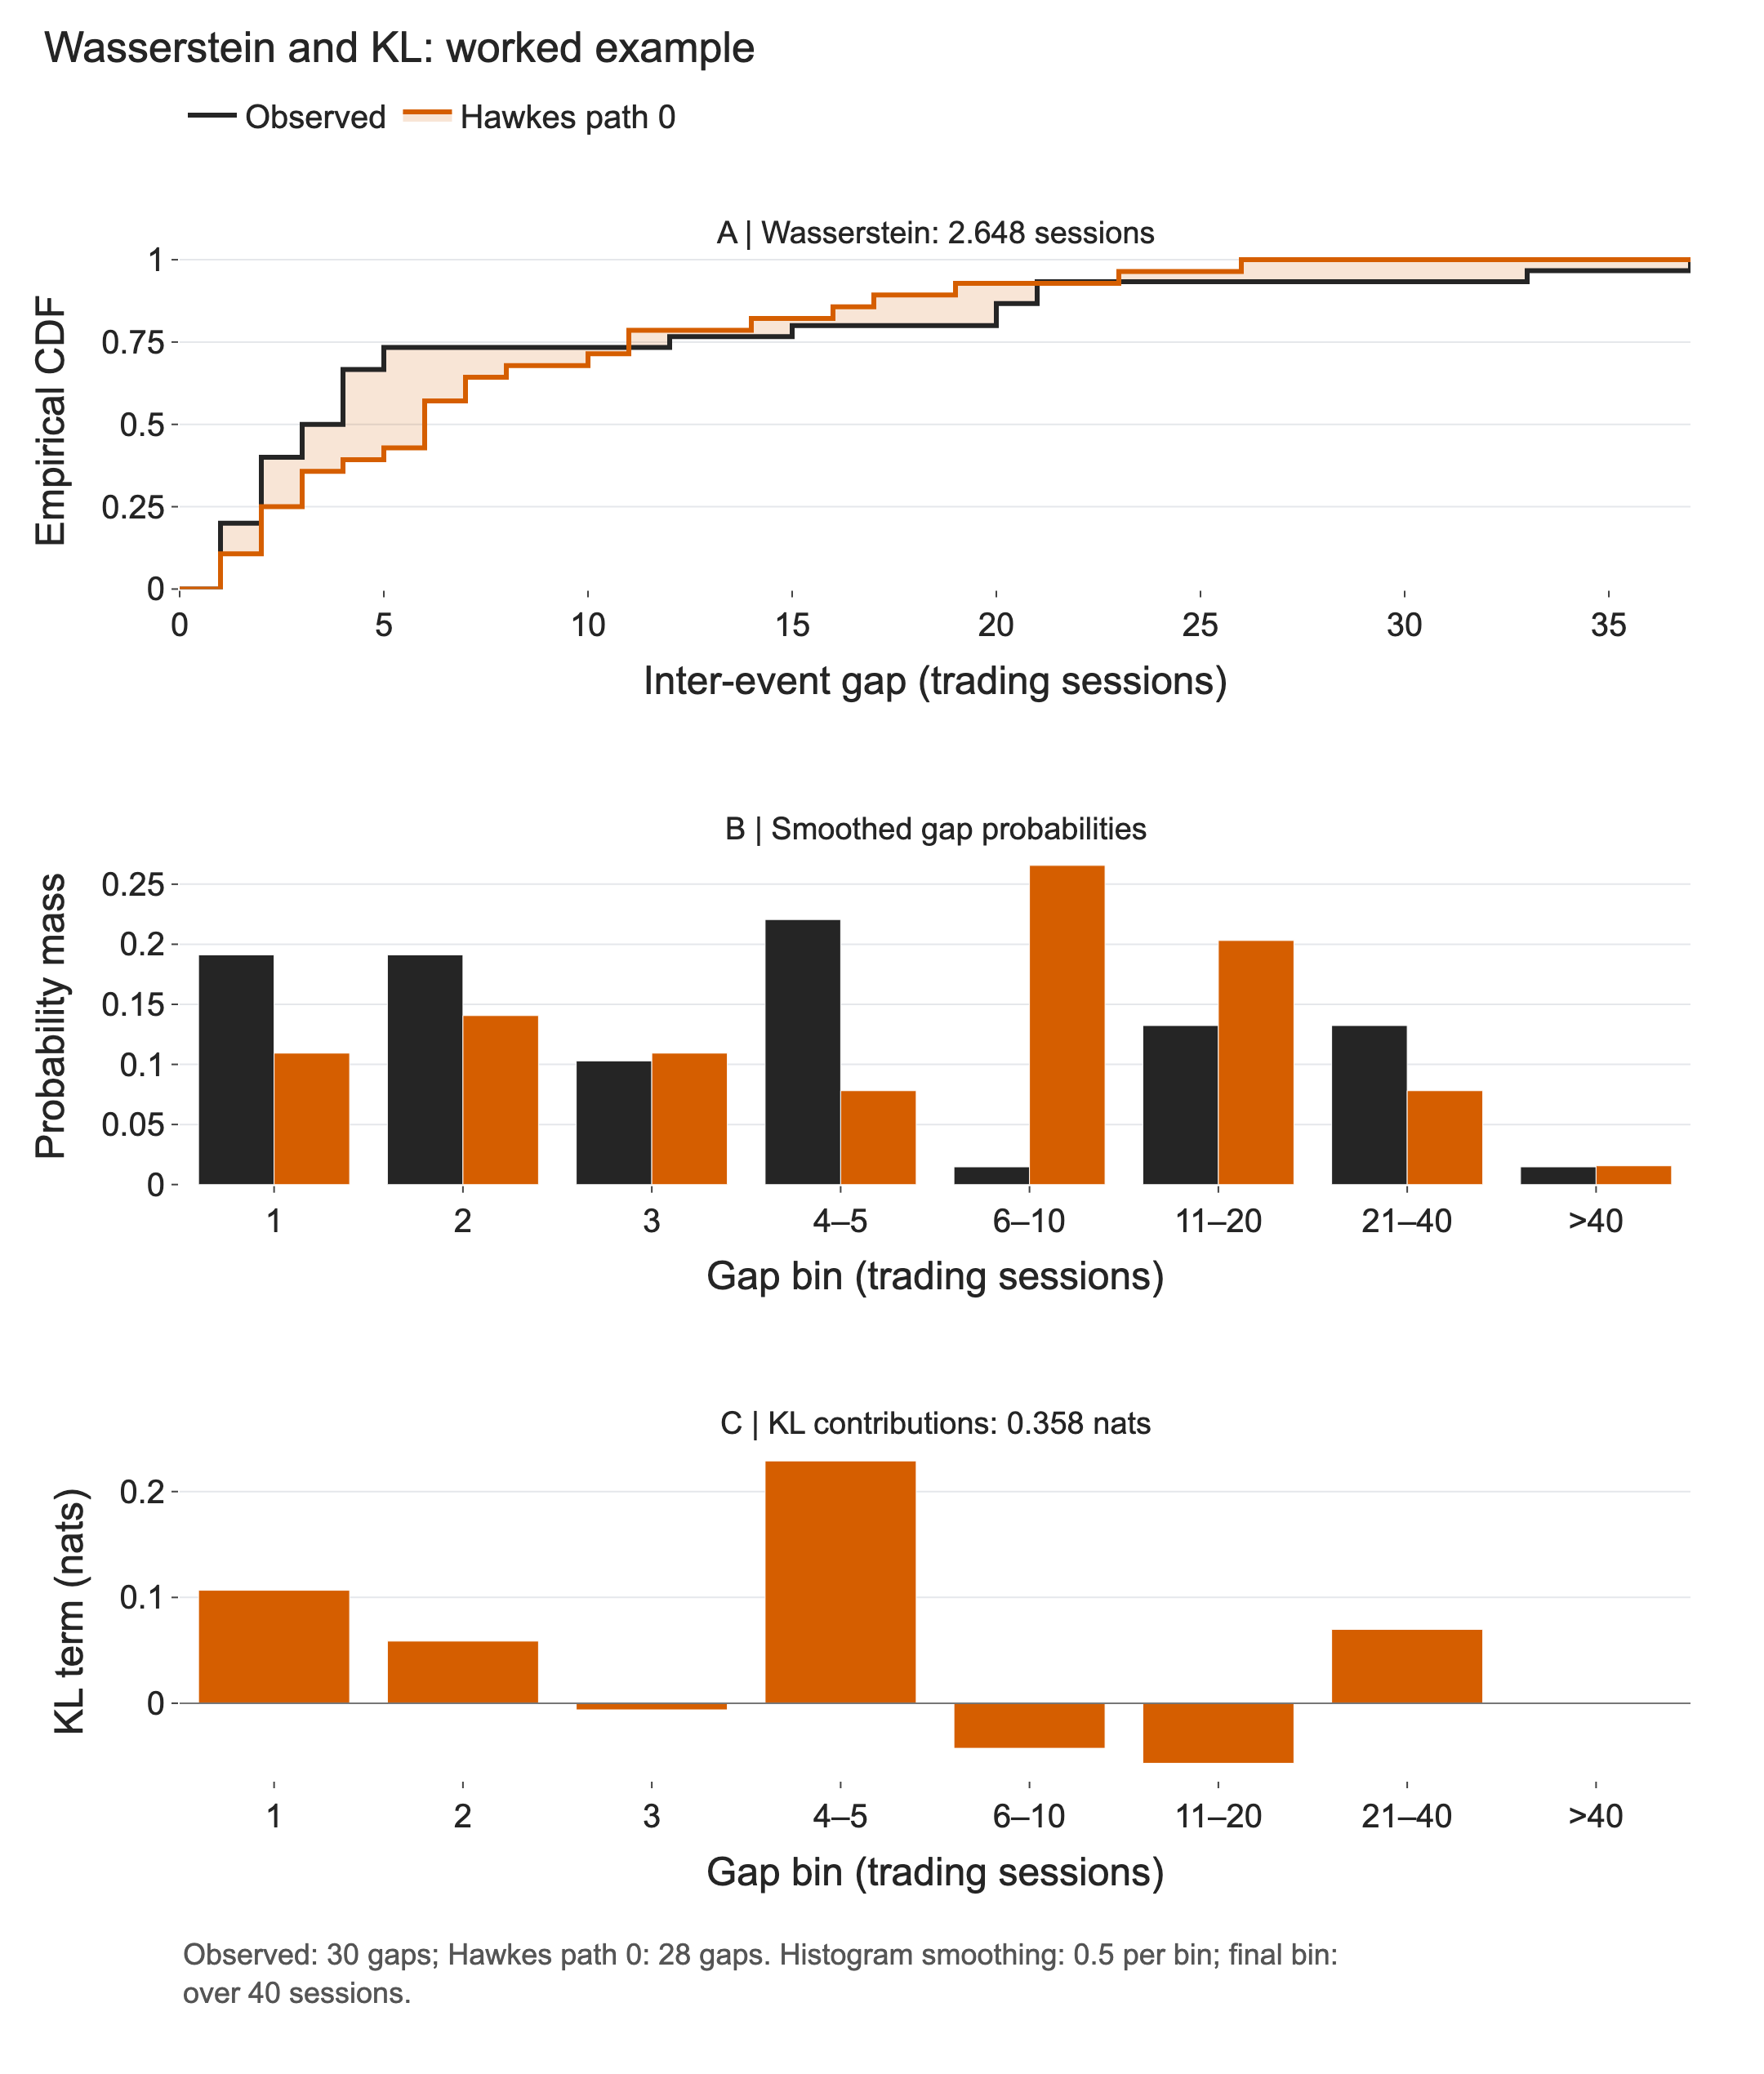

In [8]:
fig = make_subplots(
    rows=3, cols=1, vertical_spacing=0.17,
    subplot_titles=[
        f"A | Wasserstein: {w1_area:.3f} sessions",
        "B | Smoothed gap probabilities",
        f"C | KL contributions: {kl_terms.sum():.3f} nats",
    ],
)
for name, values, color in [("Observed", observed_cdf, COLORS["Observed"]),
                             ("Hawkes path 0", example_cdf, COLORS["Hawkes"])]:
    fig.add_trace(go.Scatter(
        x=support, y=values, name=name, legendgroup=name, mode="lines",
        line=dict(color=color, width=3, shape="hv"),
        fill="tonexty" if name == "Hawkes path 0" else None,
        fillcolor="rgba(213,94,0,0.16)",
    ), row=1, col=1)
for name, values, color in [("Observed", p, COLORS["Observed"]),
                             ("Hawkes path 0", q, COLORS["Hawkes"])]:
    fig.add_trace(go.Bar(x=gap_labels, y=values, name=name, legendgroup=name,
                         showlegend=False, marker_color=color), row=2, col=1)
fig.add_trace(go.Bar(x=gap_labels, y=kl_terms, showlegend=False,
                     marker_color=COLORS["Hawkes"]), row=3, col=1)
fig.add_hline(y=0, line_width=1, line_color="#777777", row=3, col=1)
fig.update_xaxes(title_text="Inter-event gap (trading sessions)", row=1, col=1)
for row in (2, 3):
    fig.update_xaxes(title_text="Gap bin (trading sessions)", type="category", row=row, col=1)
fig.update_yaxes(title_text="Empirical CDF", range=[0, 1.02], dtick=0.25, row=1, col=1)
fig.update_yaxes(title_text="Probability mass", rangemode="tozero", row=2, col=1)
fig.update_yaxes(title_text="KL term (nats)", row=3, col=1)
fig.update_layout(title="Wasserstein and KL: worked example", barmode="group", showlegend=True)
show_figure(
    fig, f"Observed: {len(observed_gaps)} gaps; Hawkes path 0: {len(example_gaps)} gaps. Histogram smoothing: 0.5 per bin; final bin: over 40 sessions.",
    height=1270,
)

In this path, 4–5-session gaps are underrepresented: 2 of 28 simulated gaps versus 7 of 30 observed gaps. This bin contributes **0.229 nats**, the largest positive term in KL. The simulated path instead places more probability on gaps of 6–20 sessions. Wasserstein integrates the resulting displacement across the whole CDF and gives **2.648 sessions**. These are different summaries of the same discrepancy; their numerical magnitudes are on different scales.

### Comparing all simulated paths

The following tables and figures return to all 300 paths per model. The fixed example above illustrates the calculation rather than representing the median result.

In [9]:
for distribution, prefix, unit in [
    ("Inter-event gaps", "gap", "sessions"),
    ("Absolute return magnitudes", "level", "log-return pp"),
]:
    rows = []
    for model in ["Hawkes", "Poisson"]:
        group = simulations[simulations.model == model]
        rows.append({
            "Model": model,
            f"Median W1 ({unit})": group[f"{prefix}_wasserstein"].median(),
            "Median KL(P||Q), nats": group[f"{prefix}_kl"].median(),
            "Median JS, nats": group[f"{prefix}_js"].median(),
        })
    show_table(pd.DataFrame(rows), f"{distribution}: 300 distances per model")


+--------------------------------------------------------------------------+
|                Inter-event gaps: 300 distances per model                 |
+---------+----------------------+-----------------------+-----------------+
| Model   | Median W1 (sessions) | Median KL(P||Q), nats | Median JS, nats |
+---------+----------------------+-----------------------+-----------------+
| Hawkes  | 3.196                | 0.330                 | 0.080           |
| Poisson | 3.308                | 0.369                 | 0.089           |
+---------+----------------------+-----------------------+-----------------+
+-------------------------------------------------------------------------------+
|              Absolute return magnitudes: 300 distances per model              |
+---------+---------------------------+-----------------------+-----------------+
| Model   | Median W1 (log-return pp) | Median KL(P||Q), nats | Median JS, nats |
+---------+---------------------------+-----------------

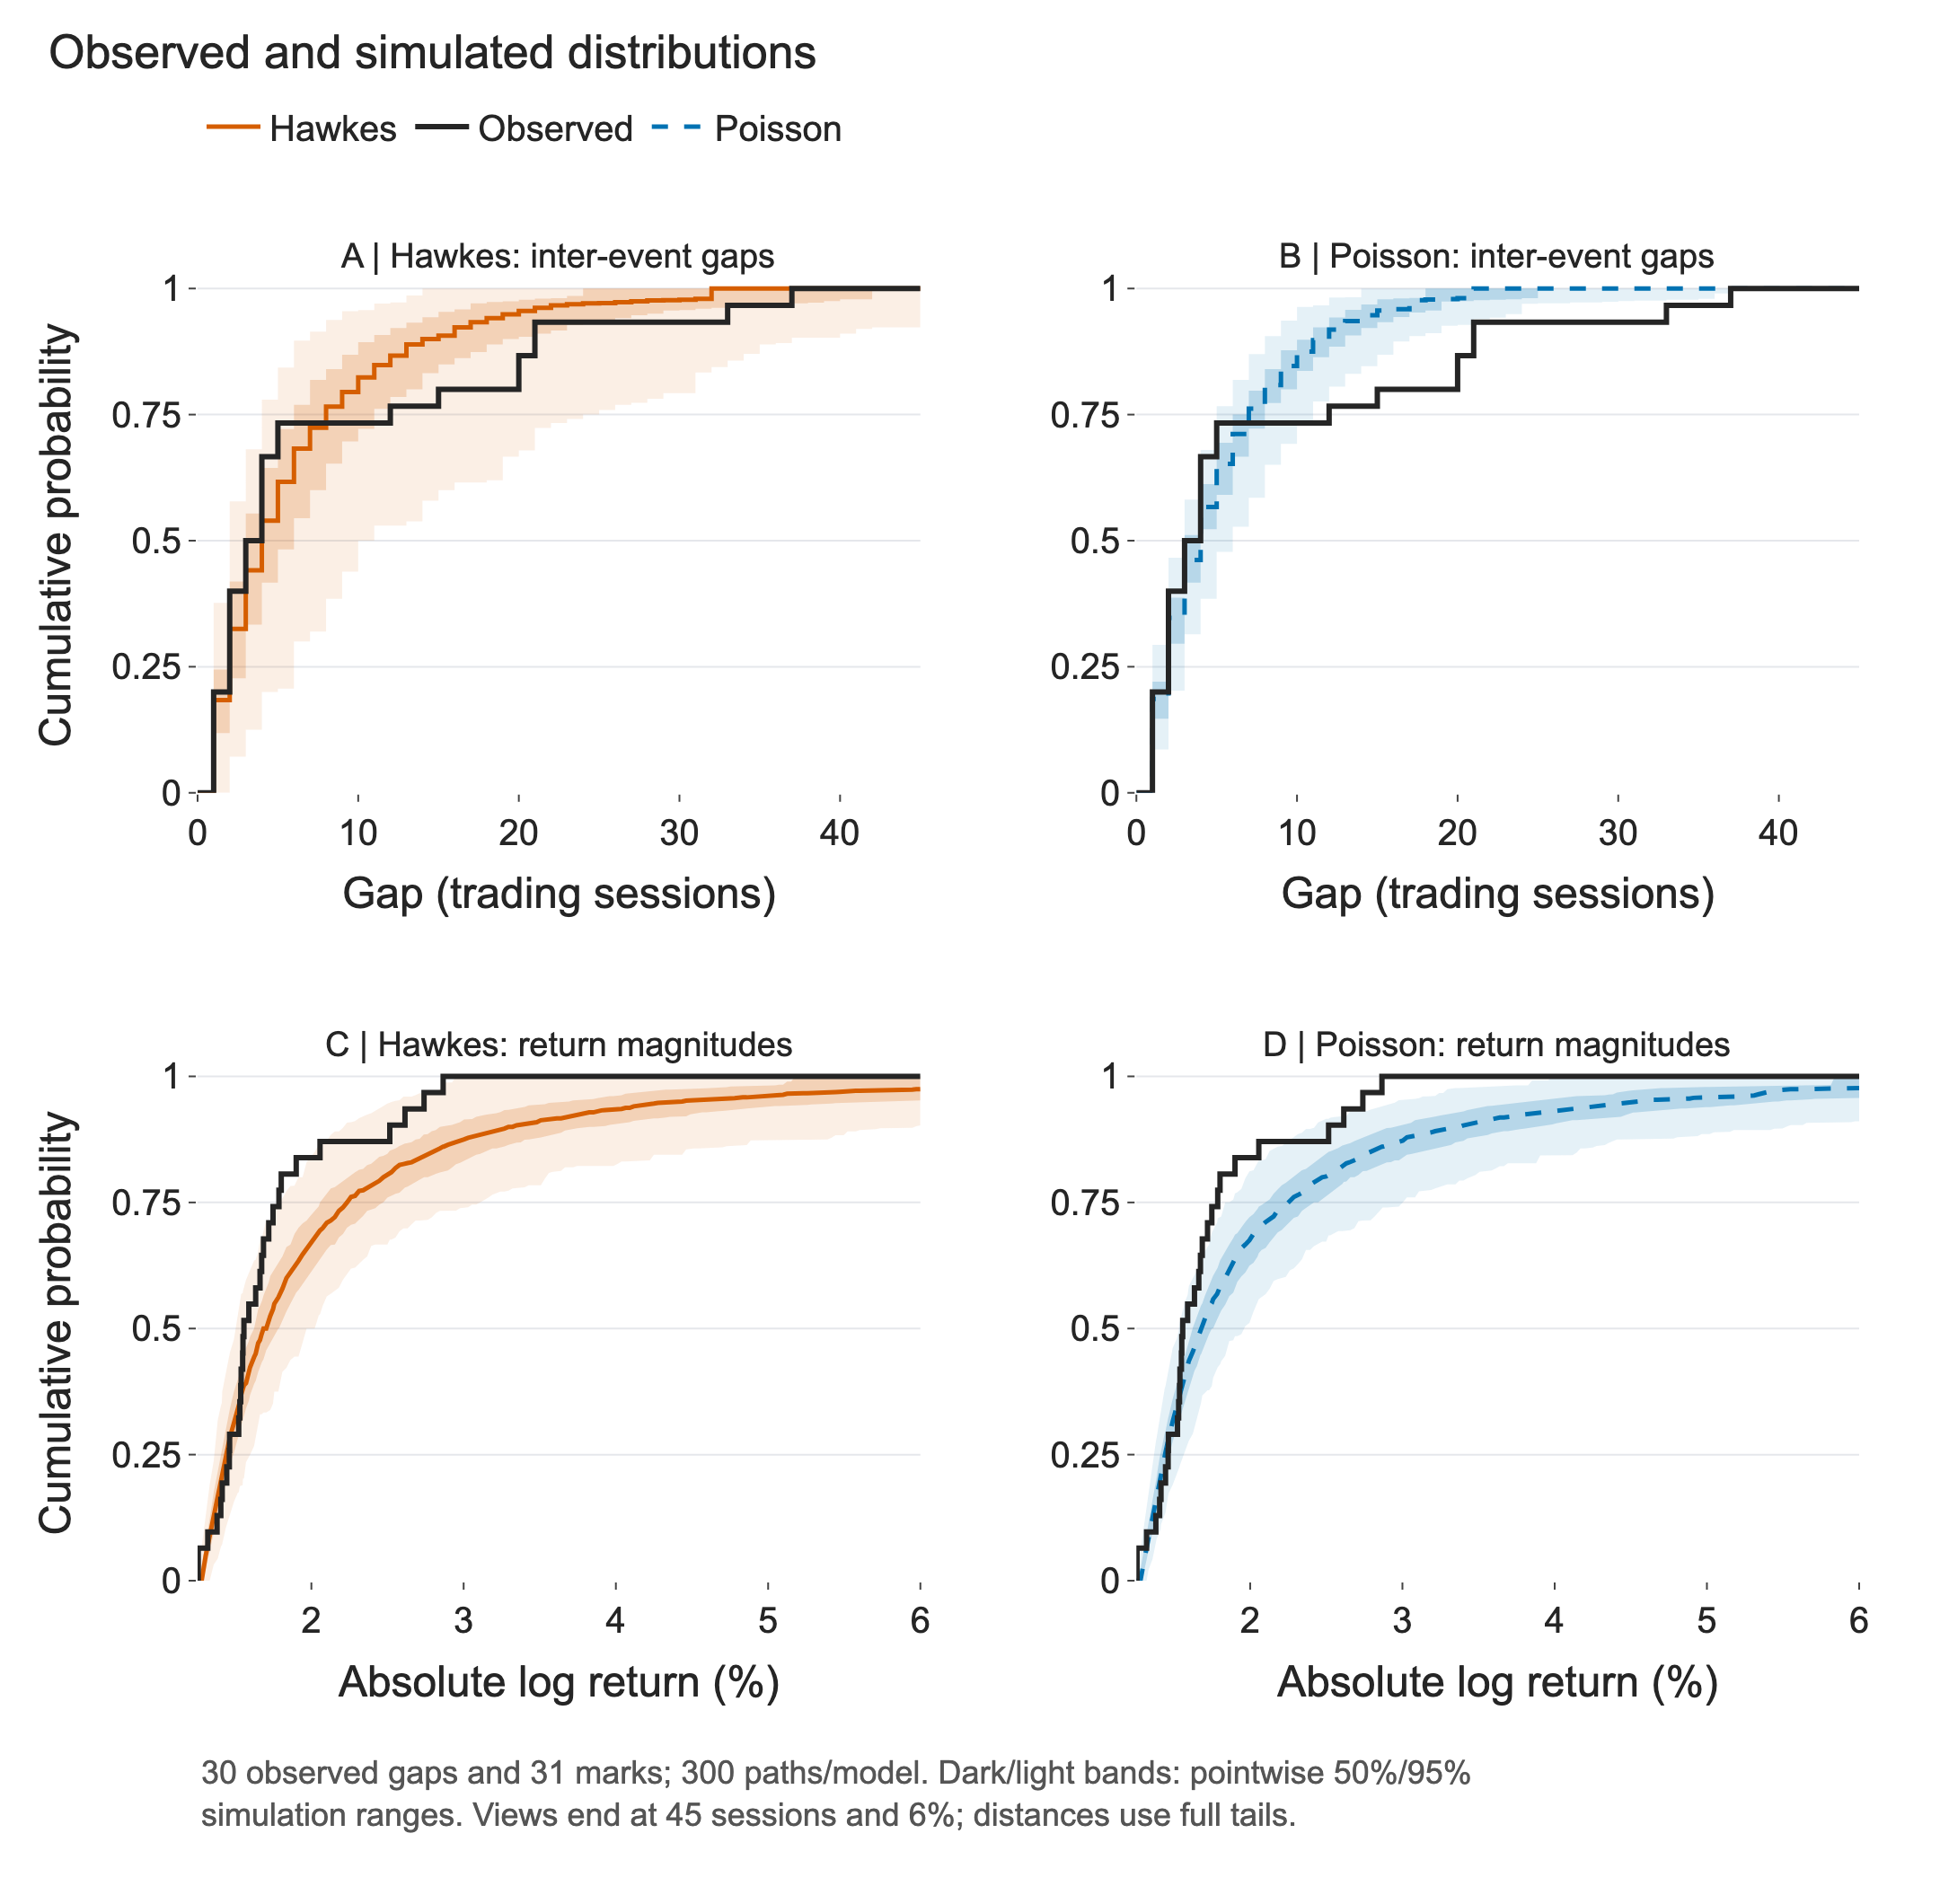

In [10]:
fig = make_subplots(
    rows=2, cols=2, horizontal_spacing=0.13, vertical_spacing=0.21,
    subplot_titles=["A | Hawkes: inter-event gaps", "B | Poisson: inter-event gaps",
                    "C | Hawkes: return magnitudes", "D | Poisson: return magnitudes"],
)
samples = [observed_gaps, test_levels * 100]
grids = [
    np.arange(0, 46),
    np.unique(np.r_[np.linspace(threshold * 100, 6, 180), test_levels * 100]),
]
for row, (values, grid) in enumerate(zip(samples, grids), 1):
    for column, model in enumerate(["Hawkes", "Poisson"], 1):
        cdfs = []
        for _, path in simulated[simulated.model == model].groupby("simulation"):
            sample = np.diff(path.day) if row == 1 else path.level_pct.to_numpy()
            cdfs.append(np.searchsorted(np.sort(sample), grid, side="right") / len(sample))
        q025, q25, median, q75, q975 = np.quantile(cdfs, [0.025, 0.25, 0.5, 0.75, 0.975], axis=0)
        shape = "hv" if row == 1 else "linear"
        rgb = "213,94,0" if model == "Hawkes" else "0,114,178"
        for lower, upper, opacity in [(q025, q975, 0.10), (q25, q75, 0.20)]:
            fig.add_trace(go.Scatter(x=grid, y=lower, mode="lines", line=dict(width=0, shape=shape), showlegend=False), row=row, col=column)
            fig.add_trace(go.Scatter(x=grid, y=upper, mode="lines", fill="tonexty", fillcolor=f"rgba({rgb},{opacity})",
                                    line=dict(width=0, shape=shape), showlegend=False), row=row, col=column)
        fig.add_trace(go.Scatter(
            x=grid, y=median, name=model, legendgroup=model, showlegend=row == 1, mode="lines",
            line=dict(color=COLORS[model], width=2.5, shape=shape, dash="dash" if model == "Poisson" else "solid"),
        ), row=row, col=column)
        fig.add_trace(go.Scatter(
            x=grid, y=np.searchsorted(np.sort(values), grid, side="right") / len(values),
            name="Observed", legendgroup="Observed", showlegend=row == 1 and column == 1, mode="lines",
            line=dict(color=COLORS["Observed"], width=3, shape="hv"),
        ), row=row, col=column)
        fig.update_xaxes(title_text="Gap (trading sessions)" if row == 1 else "Absolute log return (%)", row=row, col=column)
        fig.update_yaxes(range=[0, 1.02], tickvals=[0, 0.25, 0.5, 0.75, 1], row=row, col=column)
    fig.update_yaxes(title_text="Cumulative probability", row=row, col=1)
fig.update_layout(title="Observed and simulated distributions", showlegend=True)
show_figure(
    fig, "30 observed gaps and 31 marks; 300 paths/model. Dark/light bands: pointwise 50%/95% simulation ranges. Views end at 45 sessions and 6%; distances use full tails.",
    height=1060,
)

Hawkes has a median interval Wasserstein distance of **3.20 sessions**, compared with **3.31** for Poisson. The difference is small relative to the variation between simulations. Its median interval KL is 0.330, compared with 0.369. Both models can miss the relatively long gaps in this quieter test period.

The magnitude Wasserstein distances are about 0.44 and 0.45 percentage points. Similarity is expected because the mark law is shared. The simulation envelopes are pointwise; coverage does not imply a simultaneous goodness-of-fit result.

The mark law overstates the tail in this test year: the largest observed magnitude is 2.87%, whereas the pooled simulated 99th percentile is 9.26%. The CDF panel shows the central range through 6% for readability; all magnitudes, including larger simulated values, enter Wasserstein and the open-ended KL/JS bin. This tail mismatch limits the use of the model for extreme-move sizing.

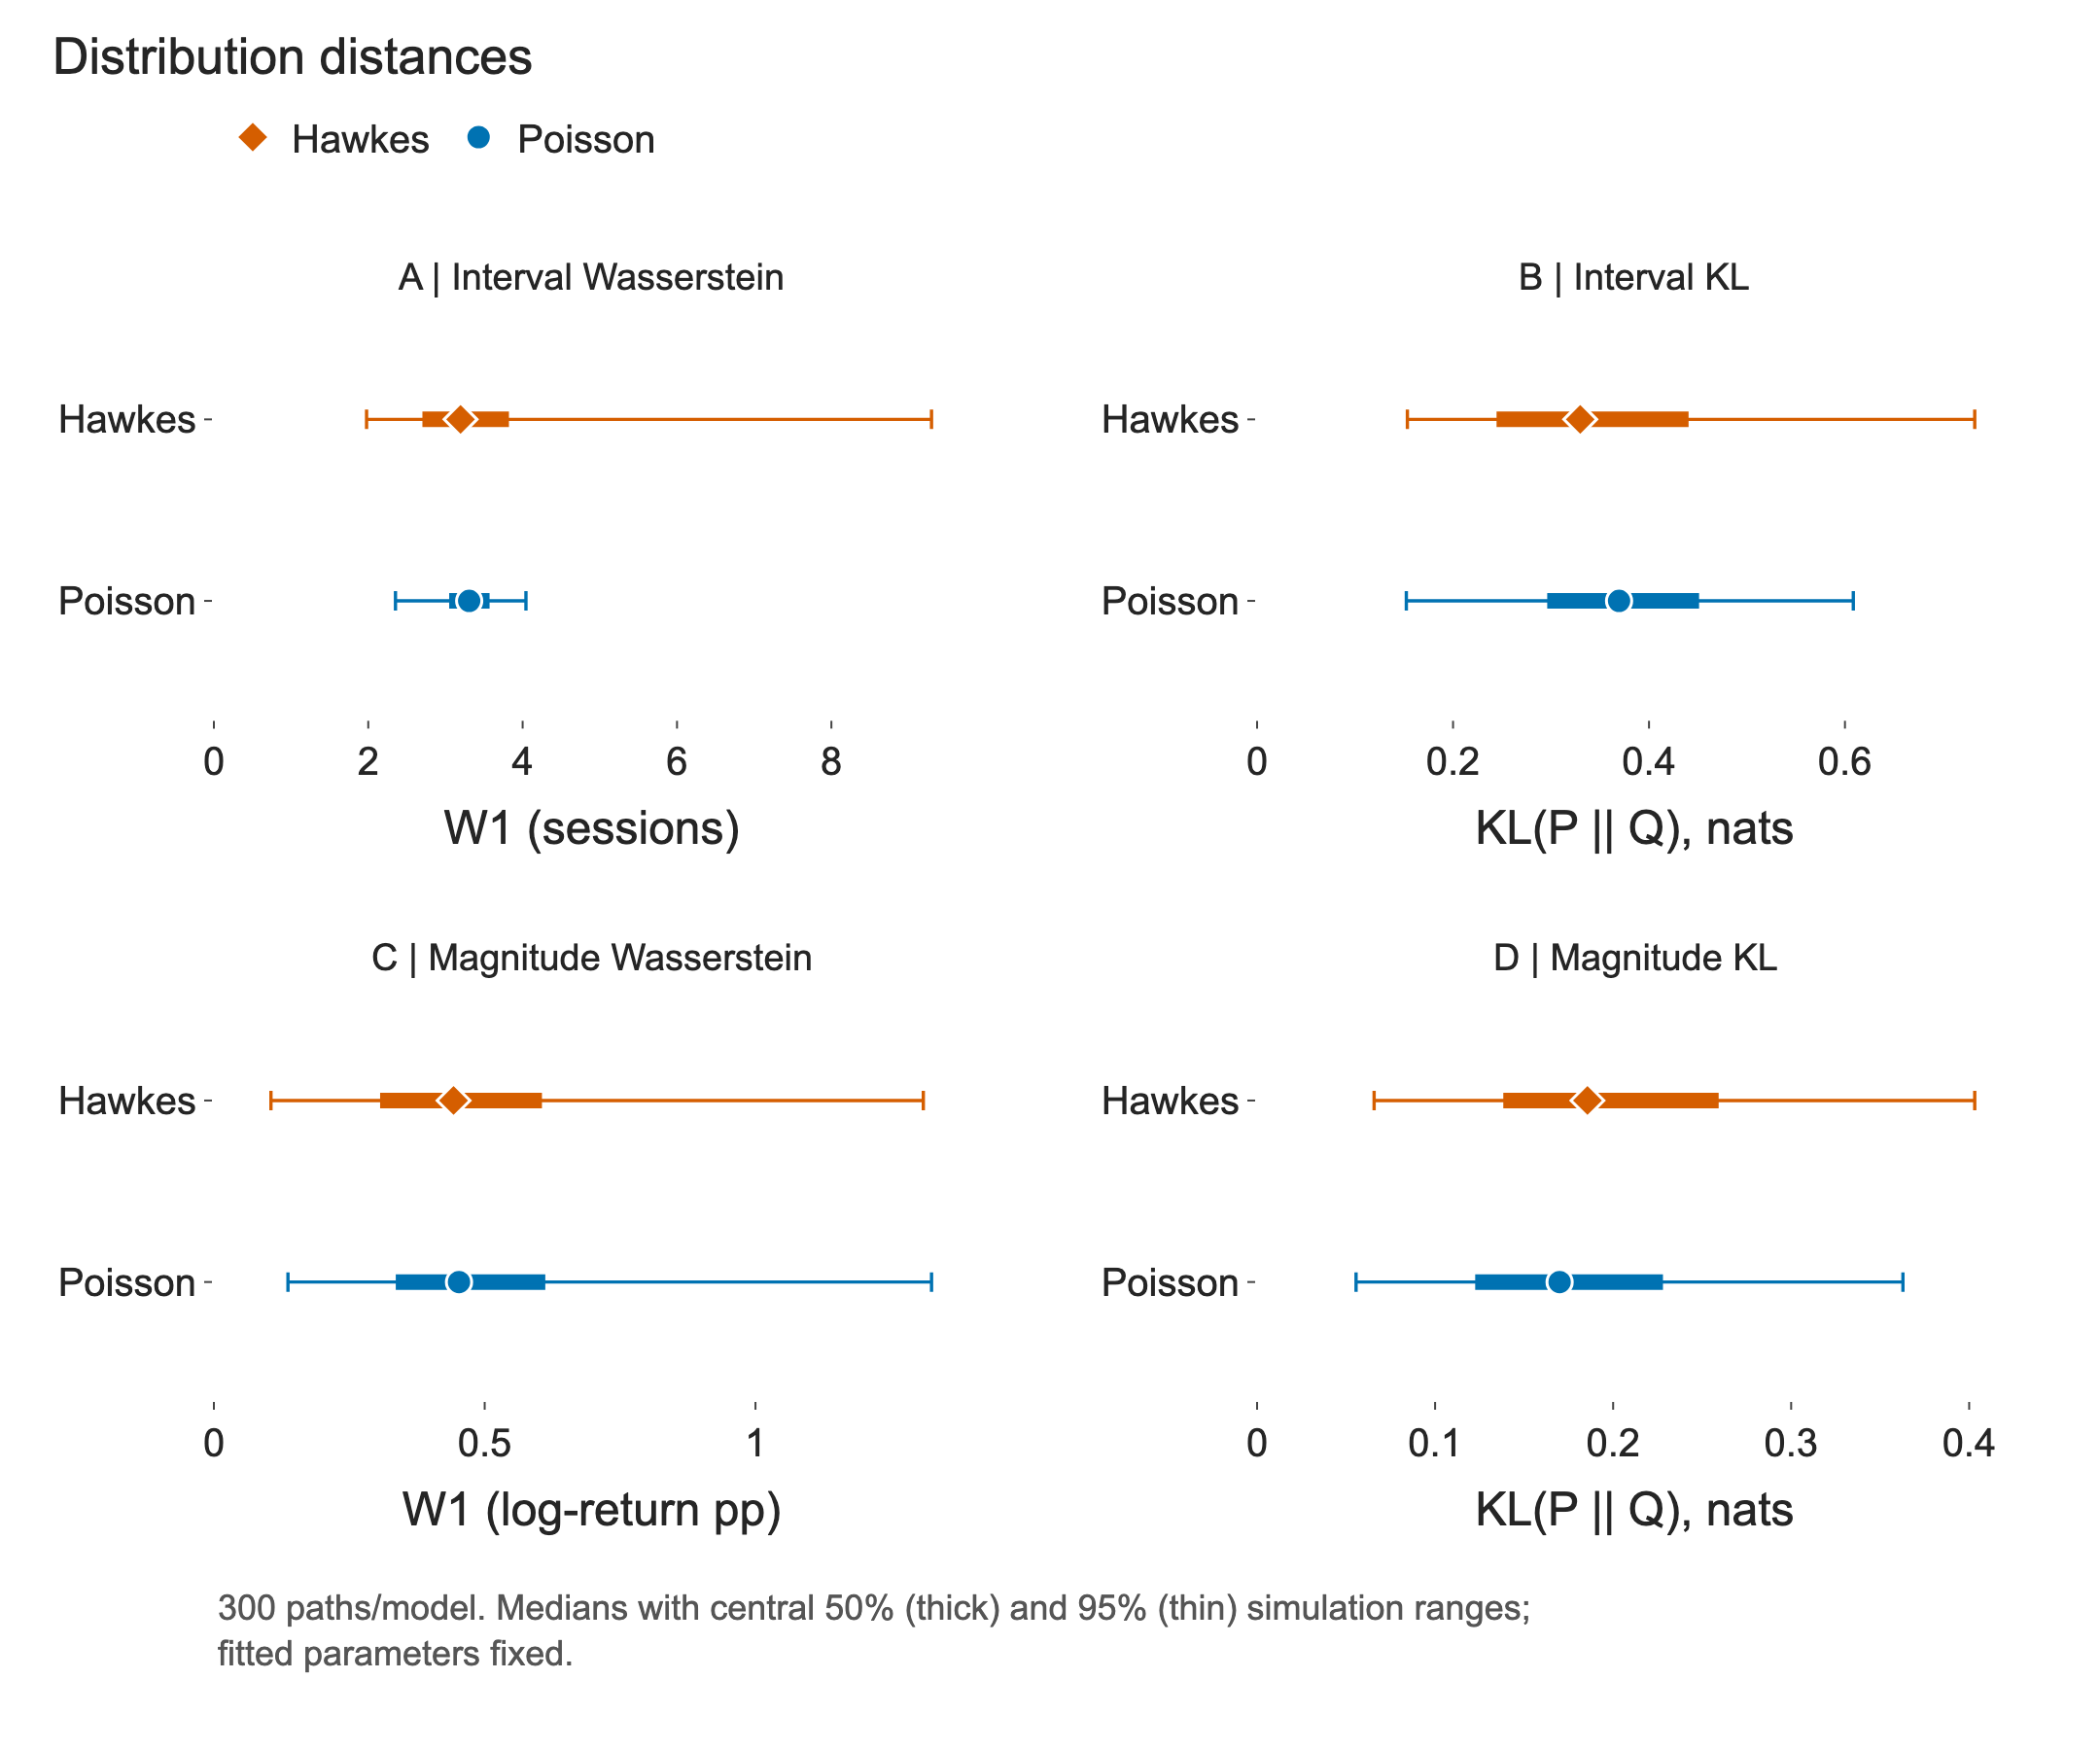

In [11]:
panels = [
    (1, 1, "gap_wasserstein", "W1 (sessions)", "A | Interval Wasserstein"),
    (1, 2, "gap_kl", "KL(P || Q), nats", "B | Interval KL"),
    (2, 1, "level_wasserstein", "W1 (log-return pp)", "C | Magnitude Wasserstein"),
    (2, 2, "level_kl", "KL(P || Q), nats", "D | Magnitude KL"),
]
fig = make_subplots(rows=2, cols=2, horizontal_spacing=0.16, vertical_spacing=0.24,
                    subplot_titles=[panel[4] for panel in panels])
for row, column, metric, unit, _ in panels:
    for model, position in [("Hawkes", 1), ("Poisson", 0)]:
        values = simulations.loc[simulations.model == model, metric]
        q025, q25, median, q75, q975 = values.quantile([0.025, 0.25, 0.5, 0.75, 0.975])
        fig.add_trace(go.Scatter(
            x=[q25, q75], y=[position, position], mode="lines", showlegend=False,
            line=dict(color=COLORS[model], width=8),
        ), row=row, col=column)
        fig.add_trace(go.Scatter(
            x=[median], y=[position], name=model, legendgroup=model,
            showlegend=row == 1 and column == 1, mode="markers",
            marker=dict(color=COLORS[model], size=13, symbol="diamond" if model == "Hawkes" else "circle",
                        line=dict(color="white", width=1.5)),
            error_x=dict(type="data", symmetric=False, array=[q975-median], arrayminus=[median-q025],
                         color=COLORS[model], thickness=1.7, width=5),
        ), row=row, col=column)
    fig.update_xaxes(title_text=unit, rangemode="tozero", showgrid=True, gridcolor="#E5E7EB", row=row, col=column)
    fig.update_yaxes(tickvals=[1, 0], ticktext=["Hawkes", "Poisson"], range=[-0.65, 1.65], showgrid=False, row=row, col=column)
fig.update_layout(title="Distribution distances", showlegend=True)
show_figure(
    fig, "300 paths/model. Medians with central 50% (thick) and 95% (thin) simulation ranges; fitted parameters fixed.",
    height=900,
)

The intervals overlap substantially. A single simulated path could reverse the ranking, which is why the result is summarized across many paths. KL additionally depends on the fixed binning and pseudocount; it should be read alongside the bin-free Wasserstein distance.

## 6. Event counts and remaining dependence



In [12]:
count_summary = []
for model in ["Hawkes", "Poisson"]:
    group = simulations[simulations.model == model]
    count_summary.append({
        "Model": model,
        "Median events": group.events.median(),
        "Events 2.5%": group.events.quantile(0.025),
        "Events 97.5%": group.events.quantile(0.975),
        "Median Fano": group.count_fano.median(),
    })
show_table(pd.DataFrame(count_summary), f"Held-out observation: {len(test_days)} event days")


+--------------------------------------------------------------------+
|                Held-out observation: 31 event days                 |
+---------+---------------+-------------+--------------+-------------+
| Model   | Median events | Events 2.5% | Events 97.5% | Median Fano |
+---------+---------------+-------------+--------------+-------------+
| Hawkes  | 36.000        | 14.000      | 69.525       | 1.352       |
| Poisson | 47.000        | 33.475      | 58.525       | 0.789       |
+---------+---------------+-------------+--------------+-------------+


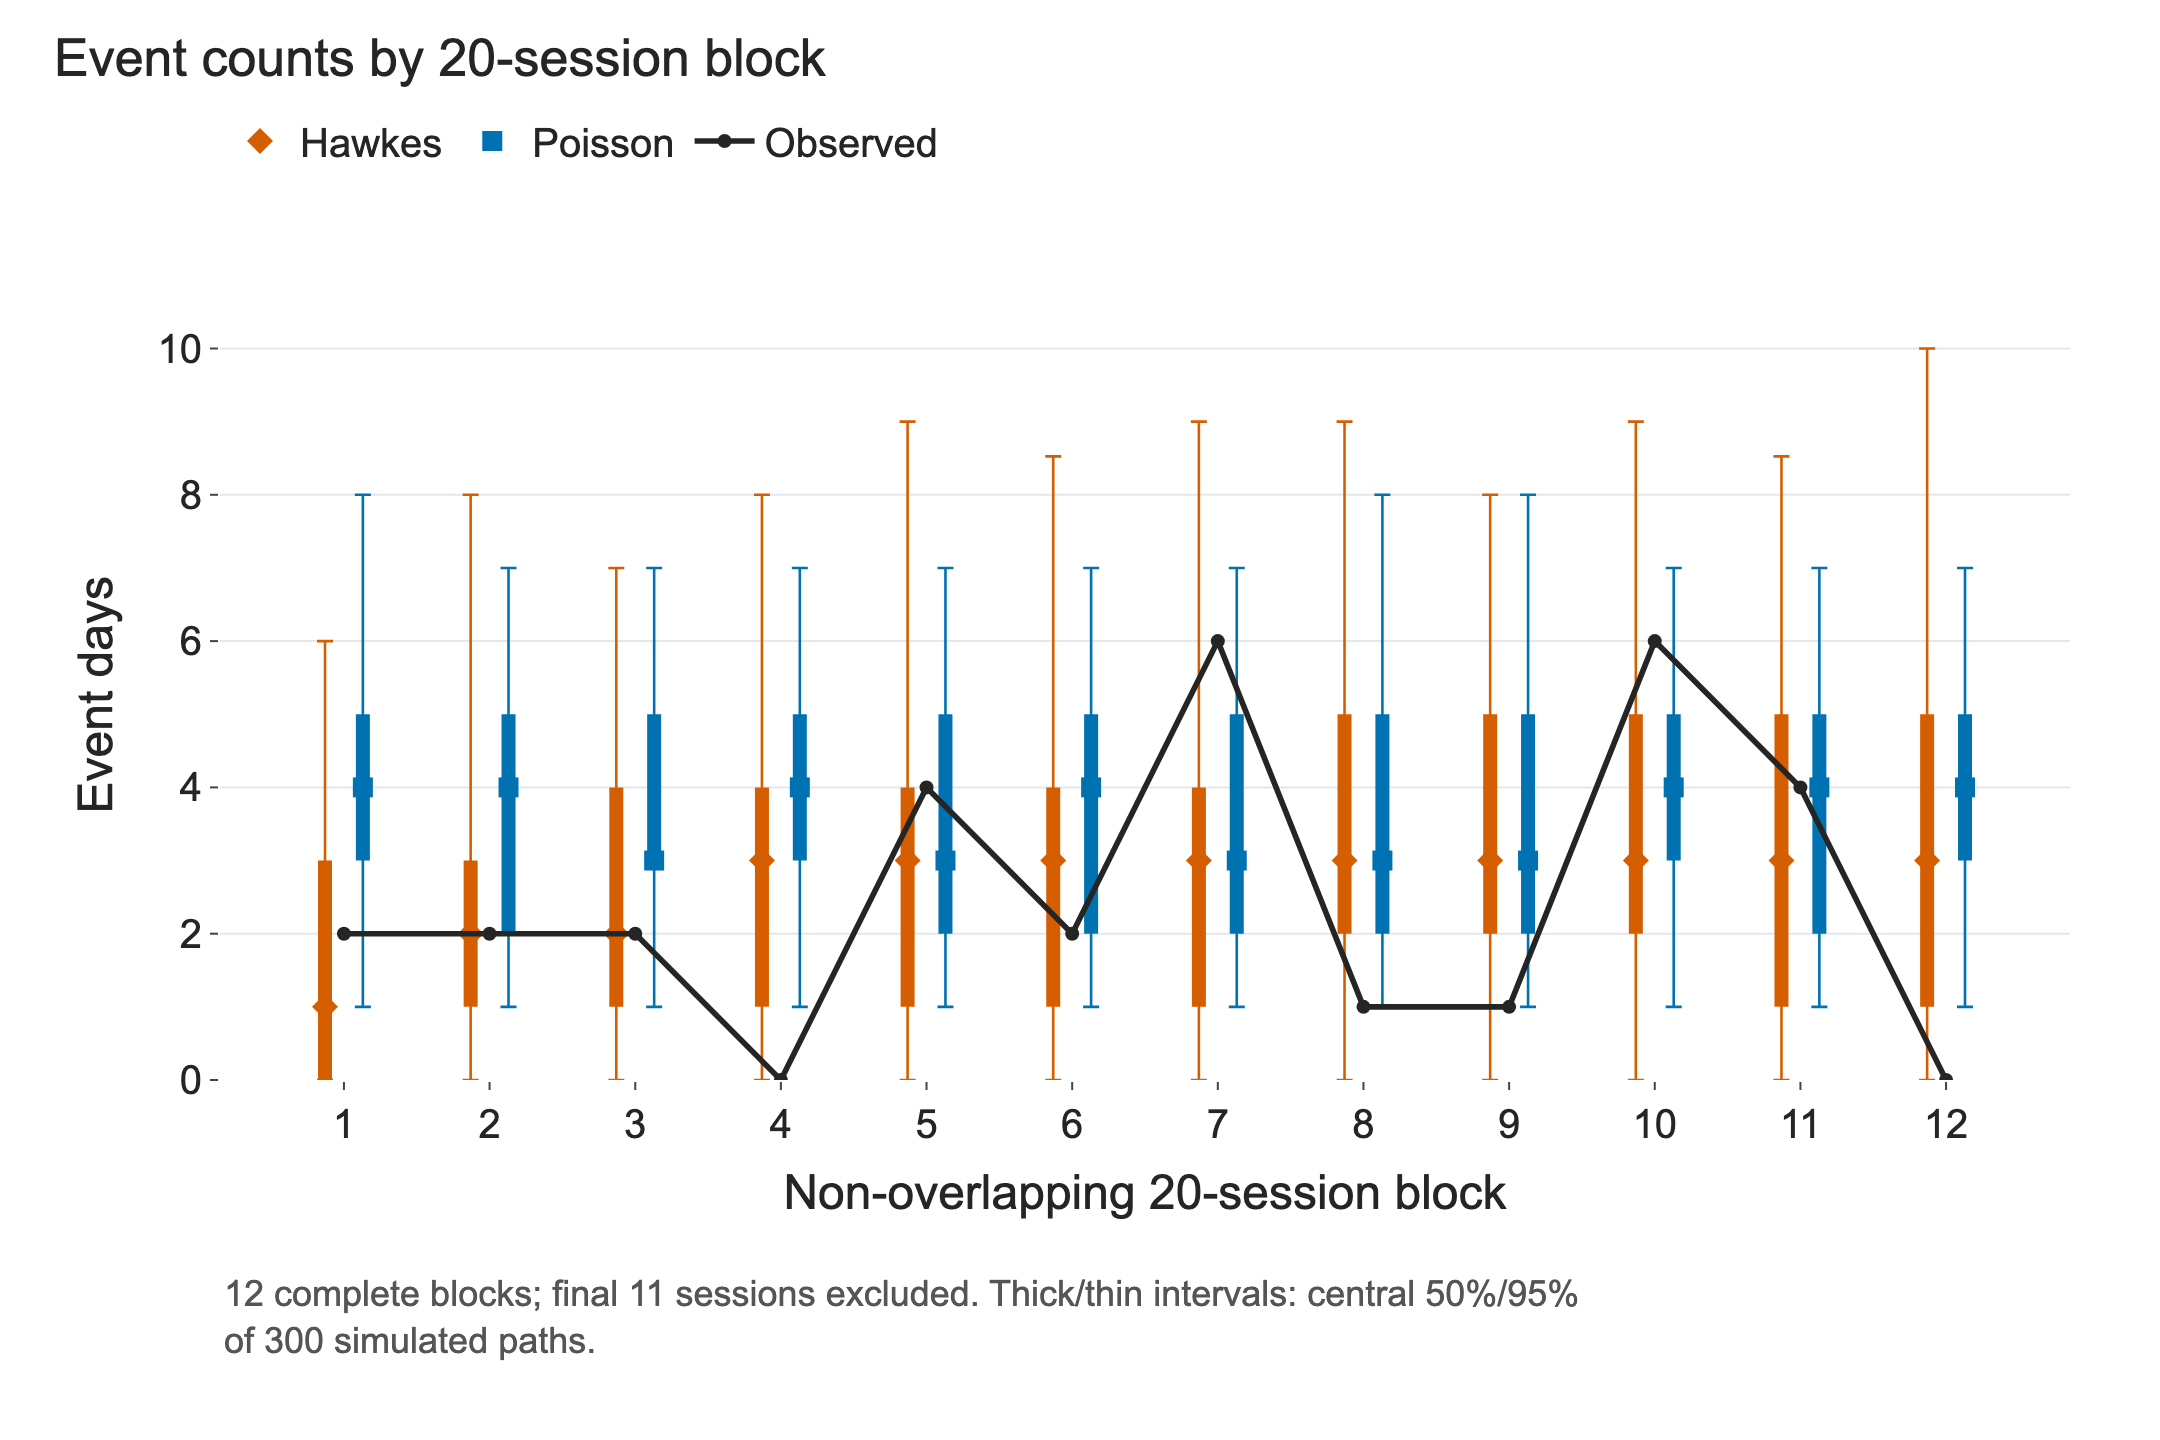

In [13]:
fig = go.Figure()
blocks = np.arange(1, len(observed_counts) + 1)
for model, offset in [("Hawkes", -0.13), ("Poisson", 0.13)]:
    matrix = count_frame[count_frame.model == model].pivot(index="simulation", columns="block", values="count").to_numpy()
    q025, q25, median, q75, q975 = np.quantile(matrix, [0.025, 0.25, 0.5, 0.75, 0.975], axis=0)
    for x, lower, upper in zip(blocks + offset, q25, q75):
        fig.add_trace(go.Scatter(x=[x, x], y=[lower, upper], mode="lines", showlegend=False,
                                line=dict(color=COLORS[model], width=7)))
    fig.add_trace(go.Scatter(
        x=blocks + offset, y=median, name=model, mode="markers",
        marker=dict(color=COLORS[model], size=10, symbol="diamond" if model == "Hawkes" else "square"),
        error_y=dict(type="data", symmetric=False, array=q975-median, arrayminus=median-q025,
                     color=COLORS[model], thickness=1.3, width=4),
    ))
fig.add_trace(go.Scatter(
    x=blocks, y=observed_counts, name="Observed", mode="lines+markers",
    line=dict(color=COLORS["Observed"], width=2.8), marker=dict(size=7),
))
fig.update_layout(title="Event counts by 20-session block",
                  xaxis_title="Non-overlapping 20-session block", yaxis_title="Event days",
                  xaxis=dict(tickvals=blocks), yaxis=dict(rangemode="tozero", dtick=2), showlegend=True)
show_figure(
    fig, "12 complete blocks; final 11 sessions excluded. Thick/thin intervals: central 50%/95% of 300 simulated paths.",
    height=720,
)

The held-out sample has 31 event days. The Hawkes median is 36, while the Poisson median is 47. Hawkes allows a wider range of quiet and active episodes. The observed 20-session count Fano factor is 1.71; the corresponding simulation medians are 1.35 and 0.79. These are based on only twelve blocks, so they provide descriptive evidence rather than a precise dispersion estimate.

Daily binning removes a median of 4 latent Hawkes arrivals and 5 Poisson arrivals per simulated test path. The continuous stationary rate therefore should not be compared directly with the observed fraction of occupied days.

As an additional check, integrated intensity between successive observed test events should resemble unit-rate exponential increments under an exact continuous-time model. After transformation $U=1-e^{-\Delta\Lambda}$, the values should resemble Uniform(0,1). The boundary-to-first-event increment is excluded from this inter-event diagnostic.

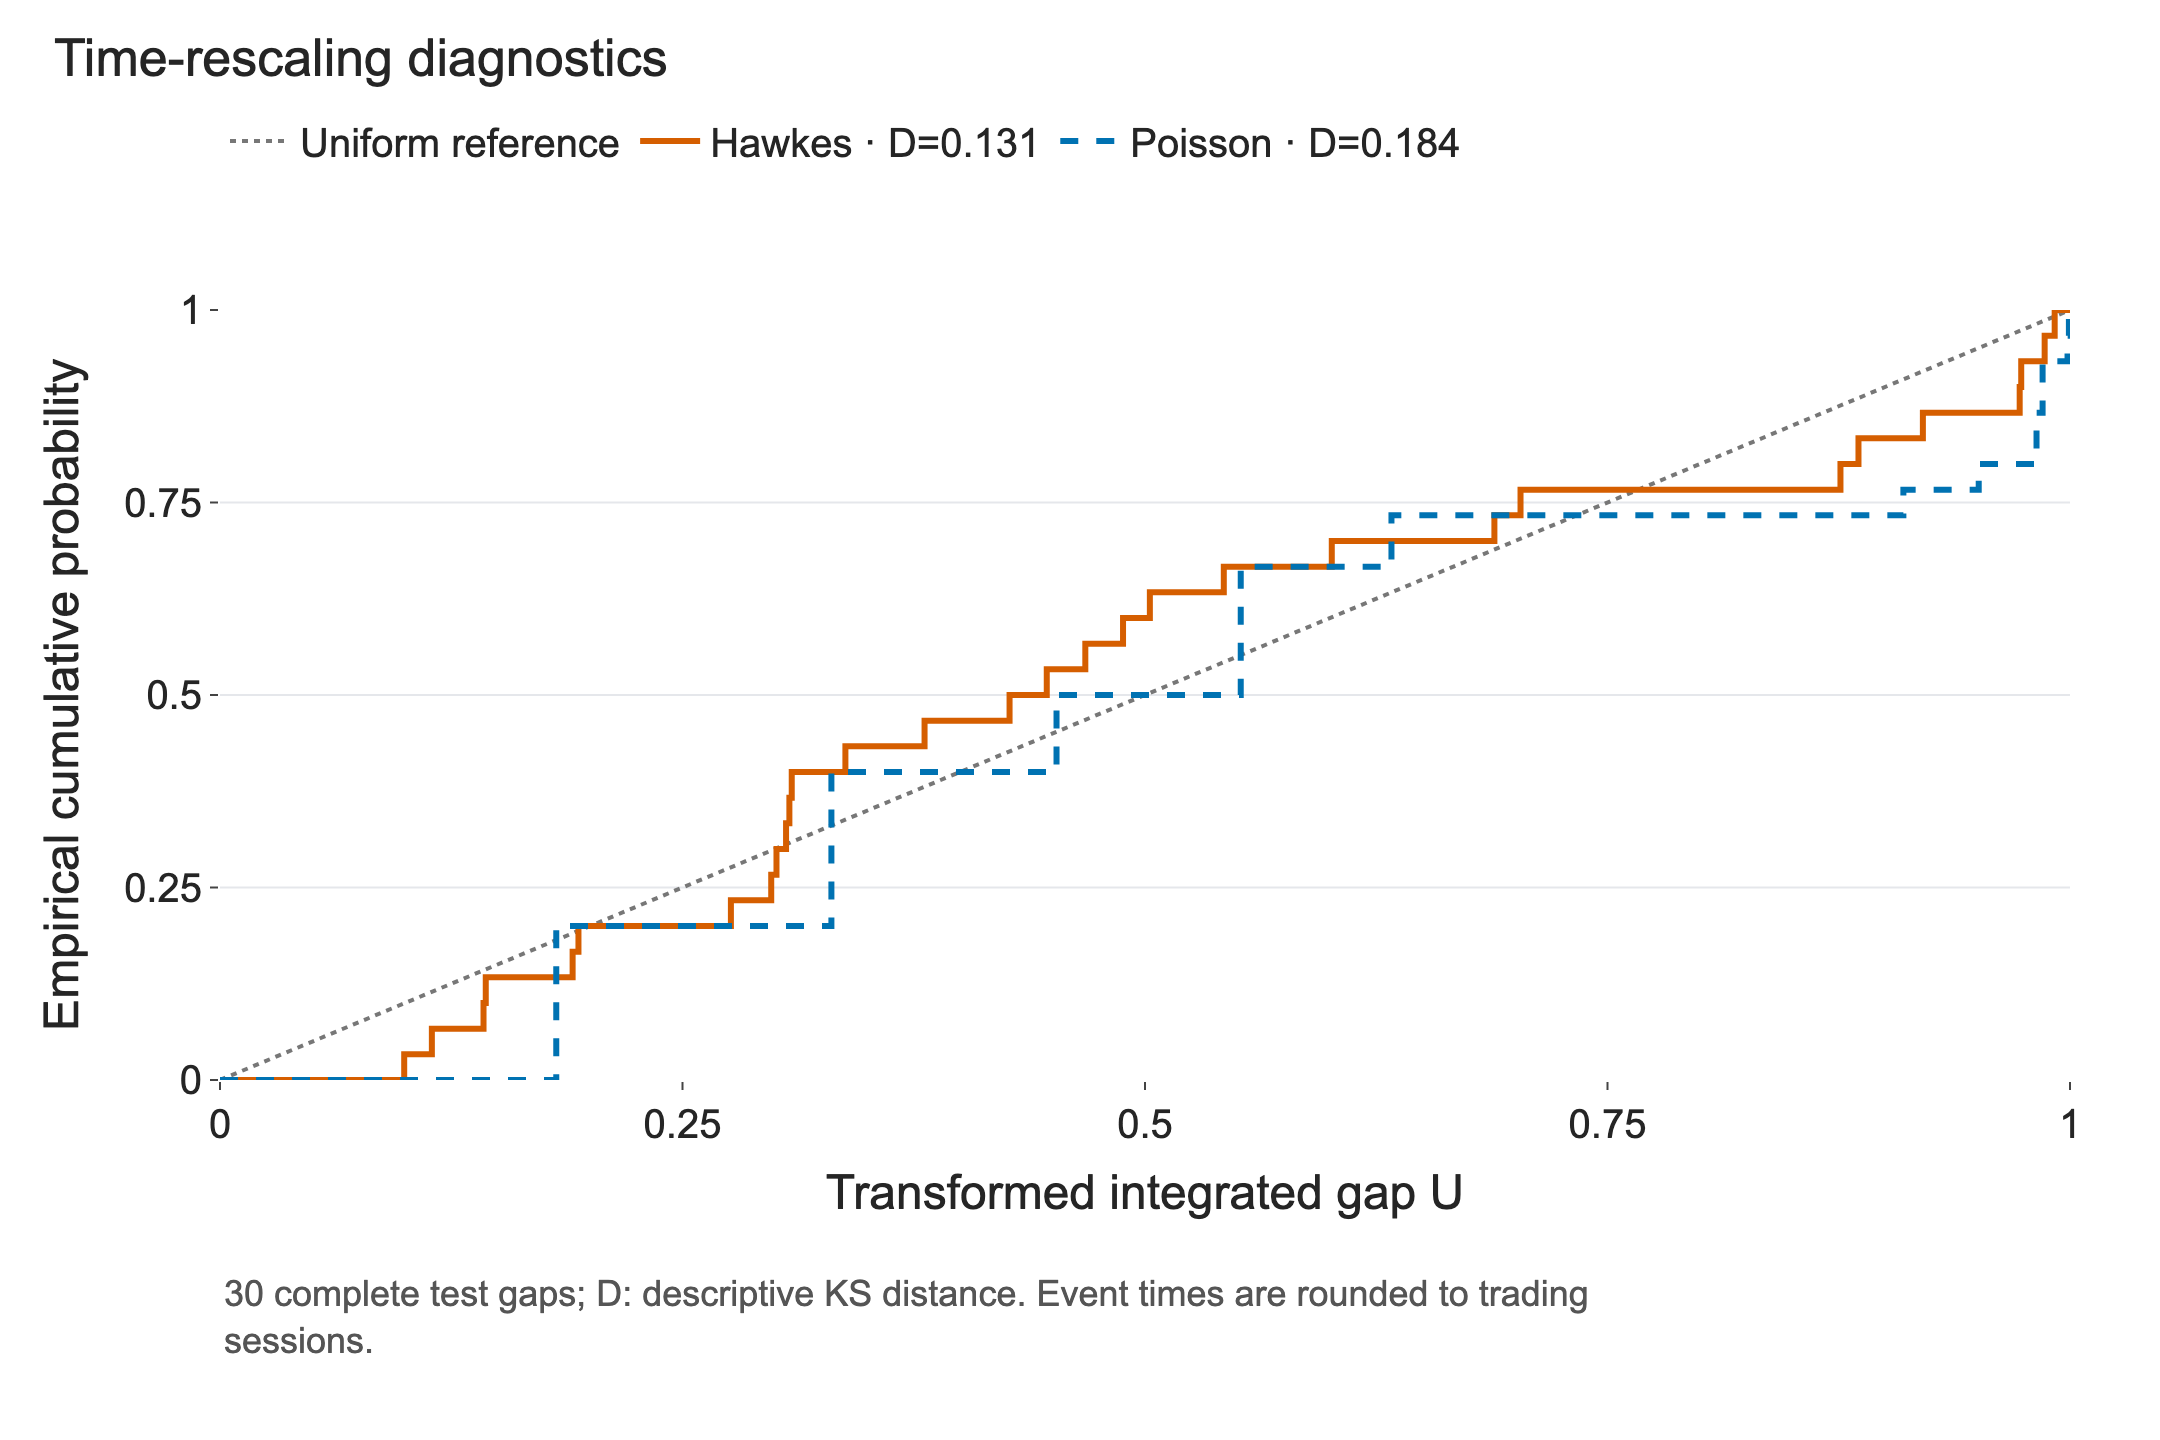

In [14]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=[0, 1], y=[0, 1], name="Uniform reference", mode="lines",
    line=dict(color="#777777", dash="dot", width=2),
))
for model in ["Hawkes", "Poisson"]:
    residual = residual_frames[model].uniform_residual.sort_values().to_numpy()
    statistic = likelihood.loc[likelihood.model == model, "rescaled_ks_d"].iloc[0]
    fig.add_trace(go.Scatter(
        x=np.r_[0, residual, 1], y=np.r_[0, np.arange(1, len(residual) + 1)/len(residual), 1],
        name=f"{model} · D={statistic:.3f}", mode="lines",
        line=dict(color=COLORS[model], width=3, shape="hv", dash="dash" if model == "Poisson" else "solid"),
    ))
fig.update_layout(
    title="Time-rescaling diagnostics",
    xaxis_title="Transformed integrated gap U", yaxis_title="Empirical cumulative probability",
    xaxis=dict(range=[0, 1], tickvals=[0, 0.25, 0.5, 0.75, 1]),
    yaxis=dict(range=[0, 1], tickvals=[0, 0.25, 0.5, 0.75, 1]), showlegend=True,
)
show_figure(
    fig, "30 complete test gaps; D: descriptive KS distance. Event times are rounded to trading sessions.",
    height=720,
)

The descriptive Kolmogorov–Smirnov distance from uniformity is 0.131 for Hawkes and 0.184 for Poisson. I do not interpret a nominal continuous-time KS p-value here: daily rounding and the small number of complete gaps change its calibration.

## 7. Conclusion

The training data support a self-exciting description: the exponential Hawkes fit improves AIC and has excitation lasting roughly 13 sessions. On the quieter held-out year it has a modest likelihood advantage, a slightly smaller median interval Wasserstein distance and more realistic count variability than a constant Poisson rate.

The advantage is limited. Simulation ranges overlap widely; only 30 complete held-out gaps are available. A fixed background intensity cannot fully adapt to volatility regimes. Daily binning hides multiple within-session arrivals, and independent lognormal marks do not model a relationship between return size and future excitation. A longer history and a model fitted directly to daily observation bins would test those assumptions more effectively.

This model reproduces statistical features of exceedance episodes. It does not reconstruct the full price path, predict the direction of a move or establish a causal market mechanism.

### References

[Laub, Taimre and Pollett, *Hawkes Processes*](https://arxiv.org/abs/1507.02822) — intensity, likelihood, simulation and residual diagnostics.

[SciPy Wasserstein-1](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html) and [KL via `scipy.stats.entropy`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.entropy.html) — definitions and argument conventions.